# Concept Importance (CF-XAI + Feature Ablation)

This notebook computes **concept importance** for three tasks:
- **Steering** (scalar regression)
- **YOLOP Drivable Area** (mean drivable probability)
- **YOLOP Lane Line** (mean lane probability)

Methods used (and only these):
- **Feature Ablation** → grid ablation saliency → aggregated into concepts
- **CF-XAI** → concept-constrained counterfactual edit → CF saliency ($|x_{cf}-x|$) → aggregated into concepts

Concepts:
- **Cityscapes semantic concepts** from Mask2Former
- **YOLOP-derived concepts**: `LaneLine`, `DrivableArea`

All outputs are exported as JSON/CSV under `analysis_exports/`.

In [100]:
# --- CRITICAL: OpenMP / MKL crash guard (Windows) ---
# If you saw: "OMP: Error #15: Initializing libiomp5md.dll, but found libiomp5md.dll already initialized"
# that is an upstream binary linkage conflict (often Torch + OpenCV + MKL/NumPy wheels).
#
# This cell MUST run before importing torch/cv2/transformers/matplotlib in this kernel session.
# If you've already imported them, restart the kernel and run this cell first.

import os
import sys

# Detect if we've already imported typical offenders
_already_loaded = any(m in sys.modules for m in ("torch", "cv2", "numpy", "sklearn", "scipy"))
if _already_loaded:
    print("WARNING: torch/cv2/numpy already imported in this session.")
    print("         Restart the kernel, then run this cell before anything else.")

# Workaround (unsafe but practical): allow duplicate OpenMP runtime instead of hard-crashing.
# Intel explicitly warns this can lead to incorrect results in rare cases; for visualization pipelines it is typically acceptable.
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

# Reduce thread contention (helps stability/perf).
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

print("Set env:")
print("  KMP_DUPLICATE_LIB_OK=", os.environ.get("KMP_DUPLICATE_LIB_OK"))
print("  OMP_NUM_THREADS=", os.environ.get("OMP_NUM_THREADS"))
print("  MKL_NUM_THREADS=", os.environ.get("MKL_NUM_THREADS"))
print("  NUMEXPR_NUM_THREADS=", os.environ.get("NUMEXPR_NUM_THREADS"))

         Restart the kernel, then run this cell before anything else.
Set env:
  KMP_DUPLICATE_LIB_OK= TRUE
  OMP_NUM_THREADS= 1
  MKL_NUM_THREADS= 1
  NUMEXPR_NUM_THREADS= 1


In [ ]:
from __future__ import annotations

from dataclasses import dataclass
from datetime import datetime
from pathlib import Path
from typing import Dict, List, Optional, Tuple


# Workspace root (set to upper project root)
ROOT = Path("/networkhome/WMGDS/safaei_d/3_generators")


@dataclass(frozen=True)
class Config:
    # Data roots (edit if your folder names differ)
    kitti_root: Path = ROOT / "data" / "data_for_new_mvp" / "KITTI"

    # NOTE:
    # In this workspace, V-KITTI is stored under data_for_new_mvp/V-KITTI (not at ROOT/V-KITTI).
    # The previous default (ROOT/"V-KITTI") does not exist here.
    vkitti_root: Path = ROOT / "data" / "data_for_new_mvp" / "V-KITTI"

    # Models / weights
    steering_weights: Path = ROOT / "models" / "weights" / "final_model.pth"
    yolop_root: Path = ROOT / "models" / "pretrained" / "YOLOP"
    yolop_weights: Path = ROOT / "models" / "pretrained" / "YOLOP" / "weights" / "End-to-end.pth"

    # Export
    export_base: Path = ROOT / "analysis_exports"

    # Repro / device
    seed: int = 1337
    device: str = "cuda"  # "cuda" or "cpu"

    # Mask2Former Cityscapes semantic segmentation
    mask2former_model_id: str = "facebook/mask2former-swin-large-cityscapes-semantic"

    # YOLOP
    yolop_square: int = 640

    # Saliency settings (keep small if you care about runtime)
    grid_size_steering: Tuple[int, int] = (12, 12)
    grid_size_yolop: Tuple[int, int] = (8, 8)

    # CF settings
    cf_steps_steering: int = 80
    cf_steps_yolop: int = 60
    cf_lr: float = 0.02
    cf_tv_weight: float = 1e-3

    # Lane/DA thresholds for concept masks (YOLOP masks are 0/1 so 0.4 is fine)
    lane_thresh: float = 0.4
    da_thresh: float = 0.4


CFG = Config()

# Create a fresh export directory for this run
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
EXPORT_DIR = CFG.export_base / f"concept_importance_{RUN_ID}"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("KITTI root:", CFG.kitti_root)
print("V-KITTI root:", CFG.vkitti_root)
print("EXPORT_DIR:", EXPORT_DIR)
print("CUDA available:", __import__("torch").cuda.is_available())

ROOT: c:\code\7_models
KITTI root: c:\code\7_models\KITTI
V-KITTI root: c:\code\7_models\data_for_new_mvp\V-KITTI
EXPORT_DIR: c:\code\7_models\analysis_exports\concept_importance_20251217_113854
CUDA available: True


In [102]:
import random
import sys

import numpy as np
import torch


def set_determinism(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_determinism(CFG.seed)

DEVICE = torch.device(CFG.device if (CFG.device == "cpu" or torch.cuda.is_available()) else "cpu")
print("Using DEVICE:", DEVICE)


def assert_dir_exists(path: Path, *, what: str) -> None:
    if not path.exists():
        # ultra explicit diagnostics
        candidates = []
        try:
            for p in (ROOT / "data_for_new_mvp").glob("**/*"):
                if p.is_dir() and p.name.lower() in {"v-kitti", "vkitti", "v_kitti"}:
                    candidates.append(str(p))
        except Exception:
            pass

        msg = [f"Missing {what} directory: {path}"]
        if candidates:
            msg.append("Found possible V-KITTI directories:")
            msg.extend([f"  - {c}" for c in sorted(set(candidates))])
        raise FileNotFoundError("\n".join(msg))


# Fail early if dataset roots are wrong
assert_dir_exists(CFG.kitti_root, what="KITTI")
assert_dir_exists(CFG.vkitti_root, what="V-KITTI")

# Hard dependency for cf_xai_core aggregation/CF resize
try:
    import cv2  # noqa: F401
except Exception as exc:
    raise RuntimeError(
        "opencv-python is required (cv2). Install via: pip install opencv-python"
    ) from exc

# Transformers for Mask2Former
try:
    from transformers import AutoImageProcessor, Mask2FormerForUniversalSegmentation
except Exception as exc:
    raise RuntimeError(
        "transformers is required for Mask2Former. Install via: pip install transformers"
    ) from exc

# Local helpers
from xai_helpers import safe_json_dump
import cf_xai_core

# For optional unletterbox helper
import paired_viz


def assert_exists(path: Path, *, what: str) -> None:
    if not path.exists():
        raise FileNotFoundError(f"Missing {what}: {path}")


assert_exists(CFG.steering_weights, what="steering weights")
assert_exists(CFG.yolop_root, what="YOLOP repo")
assert_exists(CFG.yolop_weights, what="YOLOP weights")

print("Dependency checks passed.")

Using DEVICE: cuda
Dependency checks passed.


In [103]:
# --- Concept universe (Cityscapes 19 + YOLOP concepts) ---

CITYSCAPES_CLASS_NAMES: List[str] = [
    "road",
    "sidewalk",
    "building",
    "wall",
    "fence",
    "pole",
    "traffic light",
    "traffic sign",
    "vegetation",
    "terrain",
    "sky",
    "person",
    "rider",
    "car",
    "truck",
    "bus",
    "train",
    "motorcycle",
    "bicycle",
]

CITYSCAPES_CLASSES: Dict[str, Dict[str, object]] = {
    name: {"id": idx} for idx, name in enumerate(CITYSCAPES_CLASS_NAMES)
}
CITYSCAPES_ID_TO_NAME: Dict[int, str] = {idx: name for idx, name in enumerate(CITYSCAPES_CLASS_NAMES)}
CITYSCAPES_NAME_TO_ID: Dict[str, int] = {name: idx for idx, name in enumerate(CITYSCAPES_CLASS_NAMES)}

# What concepts are considered eligible to edit for CF-XAI per task.
# Keep this explicit; change lists to match your hypothesis.
TASK_RELEVANT_CONCEPTS: Dict[str, Dict[str, List[str]]] = {
    "steering": {
        "critical": ["road", "car", "traffic sign", "traffic light"],
        "important": ["sidewalk", "person", "vegetation", "sky"],
    },
    "yolop_da": {
        "critical": ["DrivableArea", "road"],
        "important": ["sidewalk", "car"],
    },
    "yolop_ll": {
        "critical": ["LaneLine", "road"],
        "important": ["DrivableArea", "traffic sign", "car"],
    },
}


def get_concept_costs(task_name: str) -> Dict[str, float]:
    # Lower cost => easier edits (since cf_xai_core uses 1/cost).
    # Keep it simple and uniform by default.
    costs = {name: 1.0 for name in CITYSCAPES_CLASS_NAMES}
    costs["LaneLine"] = 1.0
    costs["DrivableArea"] = 1.0
    return costs


cf_xai_core.bind_context(
    cityscapes_classes=CITYSCAPES_CLASSES,
    cityscapes_id_to_name=CITYSCAPES_ID_TO_NAME,
    cityscapes_name_to_id=CITYSCAPES_NAME_TO_ID,
    task_relevant_concepts=TASK_RELEVANT_CONCEPTS,
    export_dir=EXPORT_DIR,
    lane_thresh=CFG.lane_thresh,
    da_thresh=CFG.da_thresh,
    get_concept_costs_fn=get_concept_costs,
)

print("Bound cf_xai_core context.")

Bound cf_xai_core context.


In [104]:
# --- Load steering model (regression) ---

from PIL import Image
from torchvision import transforms
import torch.nn as nn


class AutonomousDrivingModel(nn.Module):
    """Minimal steering model architecture (matches training script)."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 24, kernel_size=5, stride=2)
        self.conv2 = nn.Conv2d(24, 36, kernel_size=5, stride=2)
        self.conv3 = nn.Conv2d(36, 48, kernel_size=5, stride=2)
        self.conv4 = nn.Conv2d(48, 64, kernel_size=3)
        self.conv5 = nn.Conv2d(64, 64, kernel_size=3)
        self.fc1 = nn.Linear(1152, 1164)
        self.fc2 = nn.Linear(1164, 100)
        self.fc3 = nn.Linear(100, 50)
        self.fc4 = nn.Linear(50, 10)
        self.fc5 = nn.Linear(10, 1)
        self.dropout = nn.Dropout(0.5)
        self.relu = nn.ReLU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.relu(self.conv3(x))
        x = self.relu(self.conv4(x))
        x = self.relu(self.conv5(x))
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x)); x = self.dropout(x)
        x = self.relu(self.fc2(x)); x = self.dropout(x)
        x = self.relu(self.fc3(x)); x = self.dropout(x)
        x = self.relu(self.fc4(x))
        x = self.fc5(x)
        return x


STEERING_INPUT_HW = (66, 200)  # (H,W)
preprocess_steering = transforms.Compose([
    transforms.Resize(STEERING_INPUT_HW),
    transforms.ToTensor(),
])

steering_model = AutonomousDrivingModel().to(DEVICE)
state_dict = torch.load(CFG.steering_weights, map_location=DEVICE)
steering_model.load_state_dict(state_dict, strict=True)
steering_model.eval()

print("Loaded steering model.")

Loaded steering model.


In [105]:
# --- Load Mask2Former (Cityscapes semantic segmentation) ---

mask2former_processor = AutoImageProcessor.from_pretrained(CFG.mask2former_model_id)
mask2former_model = Mask2FormerForUniversalSegmentation.from_pretrained(CFG.mask2former_model_id).to(DEVICE)
mask2former_model.eval()

print("Loaded Mask2Former:", CFG.mask2former_model_id)

c:\Users\safaei_D\AppData\Local\anaconda3\envs\k2vktrain311\Lib\site-packages\transformers\utils\deprecation.py:165: UserWarning: The following named arguments are not valid for `Mask2FormerImageProcessor.__init__` and were ignored: '_max_size'
  return func(*args, **kwargs)


Loaded Mask2Former: facebook/mask2former-swin-large-cityscapes-semantic


In [106]:
# --- Load YOLOP (Lane line + Drivable area) ---

# YOLOP is vendored under models/pretrained/YOLOP
if str(CFG.yolop_root) not in sys.path:
    sys.path.insert(0, str(CFG.yolop_root))

from lib.config import cfg as yolop_cfg  # type: ignore
from lib.models import get_net  # type: ignore


yolop_model = get_net(yolop_cfg)
ckpt = torch.load(CFG.yolop_weights, map_location=DEVICE)
if isinstance(ckpt, dict) and "state_dict" in ckpt:
    yolop_model.load_state_dict(ckpt["state_dict"], strict=True)
else:
    # fallback if the checkpoint is itself a state_dict
    yolop_model.load_state_dict(ckpt, strict=True)

yolop_model.to(DEVICE).eval()

YOLOP_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
YOLOP_STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

print("Loaded YOLOP.")

Loaded YOLOP.


In [107]:
# --- IO + preprocessing helpers ---

import glob


def load_pil(path: Path) -> Image.Image:
    return Image.open(path).convert("RGB")


def find_first_image(root: Path) -> Path:
    """Return the first image found under root.

    Ultra-explicit failure modes:
    - if root doesn't exist: tell you immediately
    - if root exists but contains no images: print what was searched
    """

    if not root.exists():
        raise FileNotFoundError(f"No such directory: {root}")

    exts = ("*.png", "*.jpg", "*.jpeg", "*.bmp")
    checked: List[str] = []
    for ext in exts:
        checked.append(ext)
        hits = sorted(root.rglob(ext))
        if hits:
            return hits[0]

    # Helpful hint: common V-KITTI layout
    hint = ""
    if any(p.name.lower().startswith("scene_") for p in root.iterdir() if p.is_dir()):
        hint = (
            "\nHint: V-KITTI often looks like scene_01/frames/rgb/Camera_0/*.jpg. "
            "Your root exists but contains no image files under the searched extensions."
        )

    raise FileNotFoundError(
        f"No images found under {root}\n"
        f"Searched extensions: {checked}{hint}"
    )


def letterbox_rgb_to_square(img_pil: Image.Image, *, square: int) -> Tuple[torch.Tensor, Dict[str, object]]:
    """Return normalized YOLOP input tensor and meta for unletterboxing."""
    rgb = np.array(img_pil.convert("RGB"), dtype=np.uint8)
    h, w = rgb.shape[:2]

    gain = min(square / float(w), square / float(h))
    new_w = int(round(w * gain))
    new_h = int(round(h * gain))
    pad_x = int(round((square - new_w) / 2.0))
    pad_y = int(round((square - new_h) / 2.0))

    resized = cv2.resize(rgb, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    canvas = np.full((square, square, 3), 114, dtype=np.uint8)
    canvas[pad_y : pad_y + new_h, pad_x : pad_x + new_w] = resized

    x = torch.from_numpy(canvas).permute(2, 0, 1).float() / 255.0
    x = x.unsqueeze(0).to(DEVICE)
    x = (x - YOLOP_MEAN) / YOLOP_STD

    meta = {
        "orig_hw": (h, w),
        "gain": gain,
        "pad_xy": (pad_x, pad_y),
        "new_hw": (new_h, new_w),
        "square": square,
    }
    return x, meta


def letterbox_mask_to_square(mask_hw: np.ndarray, *, meta: Dict[str, object], interpolation: str) -> np.ndarray:
    square = int(meta["square"])
    new_h, new_w = meta["new_hw"]
    pad_x, pad_y = meta["pad_xy"]

    interp = cv2.INTER_NEAREST if interpolation == "nearest" else cv2.INTER_LINEAR
    resized = cv2.resize(mask_hw, (int(new_w), int(new_h)), interpolation=interp)

    canvas = np.zeros((square, square), dtype=resized.dtype)
    canvas[int(pad_y) : int(pad_y) + int(new_h), int(pad_x) : int(pad_x) + int(new_w)] = resized
    return canvas


def unletterbox_square_to_raw(map_square: np.ndarray, *, meta: Dict[str, object]) -> np.ndarray:
    h, w = meta["orig_hw"]
    square = int(meta["square"])
    return paired_viz._unletterbox_from_square(map_square, (int(h), int(w)), square=square)


def yolop_predict_masks(img_pil: Image.Image) -> Dict[str, np.ndarray]:
    """Run YOLOP once and return lane/DA probability maps in square and raw coords."""
    x, meta = letterbox_rgb_to_square(img_pil, square=CFG.yolop_square)

    with torch.no_grad():
        _, da_logits, ll_logits = yolop_model(x)

    da_prob = torch.softmax(da_logits, dim=1)[:, 1]  # (1,H,W)
    ll_prob = torch.softmax(ll_logits, dim=1)[:, 1]

    da_sq = da_prob[0].detach().cpu().numpy().astype(np.float32)
    ll_sq = ll_prob[0].detach().cpu().numpy().astype(np.float32)

    da_raw = unletterbox_square_to_raw(da_sq, meta=meta).astype(np.float32)
    ll_raw = unletterbox_square_to_raw(ll_sq, meta=meta).astype(np.float32)

    return {
        "meta": meta,
        "da_sq": da_sq,
        "ll_sq": ll_sq,
        "da_raw": da_raw,
        "ll_raw": ll_raw,
    }


def mask2former_cityscapes_seg(img_pil: Image.Image) -> np.ndarray:
    return cf_xai_core.generate_cityscapes_segmentation_mask2former(
        img_pil, mask2former_model, mask2former_processor, device=DEVICE, verbose=False
    )


def to_steering_tensor(img_pil: Image.Image) -> torch.Tensor:
    x = preprocess_steering(img_pil).unsqueeze(0).to(DEVICE)
    return x


print("Helpers ready.")

Helpers ready.


In [108]:
# --- Targets + analysis pipeline ---

from typing import Any


def steering_target_fn(model: torch.nn.Module, x: torch.Tensor) -> torch.Tensor:
    y = model(x)
    return y.view(-1)


def yolop_da_target_fn(model: torch.nn.Module, x: torch.Tensor) -> torch.Tensor:
    _, da_logits, _ = model(x)
    da_prob = torch.softmax(da_logits, dim=1)[:, 1]
    return da_prob.mean(dim=(1, 2))


def yolop_ll_target_fn(model: torch.nn.Module, x: torch.Tensor) -> torch.Tensor:
    _, _, ll_logits = model(x)
    ll_prob = torch.softmax(ll_logits, dim=1)[:, 1]
    return ll_prob.mean(dim=(1, 2))


def torch_map_from_np(map_hw: np.ndarray) -> torch.Tensor:
    t = torch.from_numpy(map_hw.astype(np.float32))
    return t.unsqueeze(0).unsqueeze(0)


def topk_concepts(concepts: Dict[str, Tuple[float, float]], k: int = 10) -> List[Tuple[str, float, float]]:
    items = [(c, float(v[0]), float(v[1])) for c, v in concepts.items()]
    items.sort(key=lambda x: x[1], reverse=True)
    return items[:k]


def run_single_image(img_path: Path) -> Dict[str, Any]:
    img = load_pil(img_path)

    seg_raw = mask2former_cityscapes_seg(img)
    yolop_masks = yolop_predict_masks(img)

    lane_raw = yolop_masks["ll_raw"]
    da_raw = yolop_masks["da_raw"]

    # Create YOLOP-aligned (square letterboxed) masks for CF
    meta = yolop_masks["meta"]
    seg_sq = letterbox_mask_to_square(seg_raw, meta=meta, interpolation="nearest")

    lane_sq = yolop_masks["ll_sq"]
    da_sq = yolop_masks["da_sq"]

    # Inputs
    x_steer = to_steering_tensor(img)
    x_yolop, _ = letterbox_rgb_to_square(img, square=CFG.yolop_square)

    out: Dict[str, Any] = {
        "image_path": str(img_path),
        "raw_hw": tuple(img.size[::-1]),
    }

    # -----------------
    # Steering
    # -----------------
    with torch.no_grad():
        steer_base = float(steering_target_fn(steering_model, x_steer).item())

    sal_ablation = cf_xai_core.feature_ablation_saliency(
        steering_model,
        x_steer,
        steering_target_fn,
        grid_size=CFG.grid_size_steering,
        device=DEVICE,
    )
    concepts_ablation = cf_xai_core.aggregate_saliency_to_concepts(
        {"ablation": sal_ablation},
        seg_raw,
        lane_mask=lane_raw,
        da_mask=da_raw,
    )

    x_cf, edit_mask = cf_xai_core.segment_constrained_counterfactual(
        steering_model,
        x_steer,
        steering_target_fn,
        task_name="steering",
        seg_mask=seg_raw,
        lane_mask=lane_raw,
        da_mask=da_raw,
        steps=CFG.cf_steps_steering,
        lr=CFG.cf_lr,
        tv_weight=CFG.cf_tv_weight,
        device=str(DEVICE),
        direction="maximize",
    )

    with torch.no_grad():
        steer_cf = float(steering_target_fn(steering_model, x_cf).item())

    sal_cf = cf_xai_core.compute_cf_saliency(x_steer, x_cf)
    concepts_cf = cf_xai_core.aggregate_saliency_to_concepts(
        {"cf": sal_cf},
        seg_raw,
        lane_mask=lane_raw,
        da_mask=da_raw,
    )

    edit_mag_by_concept, edit_mag_global = cf_xai_core.compute_edit_magnitude_by_concept(
        x_steer,
        x_cf,
        seg_raw,
        lane_mask=lane_raw,
        da_mask=da_raw,
    )

    out["steering"] = {
        "base_pred": steer_base,
        "cf_pred": steer_cf,
        "ablation_top10": topk_concepts(concepts_ablation, k=10),
        "cf_top10": topk_concepts(concepts_cf, k=10),
        "ablation_concepts": concepts_ablation,
        "cf_concepts": concepts_cf,
        "cf_edit_mask_sum": int(np.array(edit_mask).sum()),
        "cf_edit_magnitude_by_concept": edit_mag_by_concept,
        "cf_edit_magnitude_global": edit_mag_global,
    }

    # -----------------
    # YOLOP Drivable Area
    # -----------------
    with torch.no_grad():
        da_base = float(yolop_da_target_fn(yolop_model, x_yolop).item())

    sal_ablation_da_sq = cf_xai_core.feature_ablation_saliency(
        yolop_model,
        x_yolop,
        yolop_da_target_fn,
        grid_size=CFG.grid_size_yolop,
        device=DEVICE,
    )

    # Unletterbox saliency to raw to avoid padding distortions in concept aggregation
    sal_ablation_da_raw = torch_map_from_np(unletterbox_square_to_raw(sal_ablation_da_sq[0, 0].detach().cpu().numpy(), meta=meta)).to(DEVICE)

    concepts_ablation_da = cf_xai_core.aggregate_saliency_to_concepts(
        {"ablation": sal_ablation_da_raw},
        seg_raw,
        lane_mask=lane_raw,
        da_mask=da_raw,
    )

    x_cf_da, edit_da = cf_xai_core.segment_constrained_counterfactual(
        yolop_model,
        x_yolop,
        yolop_da_target_fn,
        task_name="yolop_da",
        seg_mask=seg_sq,
        lane_mask=lane_sq,
        da_mask=da_sq,
        steps=CFG.cf_steps_yolop,
        lr=CFG.cf_lr,
        tv_weight=CFG.cf_tv_weight,
        device=str(DEVICE),
        direction="maximize",
        clamp_to_input_range=True,
    )

    with torch.no_grad():
        da_cf = float(yolop_da_target_fn(yolop_model, x_cf_da).item())

    sal_cf_da_sq = cf_xai_core.compute_cf_saliency(x_yolop, x_cf_da)
    sal_cf_da_raw = torch_map_from_np(unletterbox_square_to_raw(sal_cf_da_sq[0, 0].detach().cpu().numpy(), meta=meta)).to(DEVICE)

    concepts_cf_da = cf_xai_core.aggregate_saliency_to_concepts(
        {"cf": sal_cf_da_raw},
        seg_raw,
        lane_mask=lane_raw,
        da_mask=da_raw,
    )

    edit_mag_by_concept_da, edit_mag_global_da = cf_xai_core.compute_edit_magnitude_by_concept(
        x_yolop,
        x_cf_da,
        seg_sq,
        lane_mask=lane_sq,
        da_mask=da_sq,
    )

    out["yolop_da"] = {
        "base_pred": da_base,
        "cf_pred": da_cf,
        "ablation_top10": topk_concepts(concepts_ablation_da, k=10),
        "cf_top10": topk_concepts(concepts_cf_da, k=10),
        "ablation_concepts": concepts_ablation_da,
        "cf_concepts": concepts_cf_da,
        "cf_edit_mask_sum": int(np.array(edit_da).sum()),
        "cf_edit_magnitude_by_concept": edit_mag_by_concept_da,
        "cf_edit_magnitude_global": edit_mag_global_da,
    }

    # -----------------
    # YOLOP Lane Line
    # -----------------
    with torch.no_grad():
        ll_base = float(yolop_ll_target_fn(yolop_model, x_yolop).item())

    sal_ablation_ll_sq = cf_xai_core.feature_ablation_saliency(
        yolop_model,
        x_yolop,
        yolop_ll_target_fn,
        grid_size=CFG.grid_size_yolop,
        device=DEVICE,
    )

    sal_ablation_ll_raw = torch_map_from_np(unletterbox_square_to_raw(sal_ablation_ll_sq[0, 0].detach().cpu().numpy(), meta=meta)).to(DEVICE)

    concepts_ablation_ll = cf_xai_core.aggregate_saliency_to_concepts(
        {"ablation": sal_ablation_ll_raw},
        seg_raw,
        lane_mask=lane_raw,
        da_mask=da_raw,
    )

    x_cf_ll, edit_ll = cf_xai_core.segment_constrained_counterfactual(
        yolop_model,
        x_yolop,
        yolop_ll_target_fn,
        task_name="yolop_ll",
        seg_mask=seg_sq,
        lane_mask=lane_sq,
        da_mask=da_sq,
        steps=CFG.cf_steps_yolop,
        lr=CFG.cf_lr,
        tv_weight=CFG.cf_tv_weight,
        device=str(DEVICE),
        direction="maximize",
        clamp_to_input_range=True,
    )

    with torch.no_grad():
        ll_cf = float(yolop_ll_target_fn(yolop_model, x_cf_ll).item())

    sal_cf_ll_sq = cf_xai_core.compute_cf_saliency(x_yolop, x_cf_ll)
    sal_cf_ll_raw = torch_map_from_np(unletterbox_square_to_raw(sal_cf_ll_sq[0, 0].detach().cpu().numpy(), meta=meta)).to(DEVICE)

    concepts_cf_ll = cf_xai_core.aggregate_saliency_to_concepts(
        {"cf": sal_cf_ll_raw},
        seg_raw,
        lane_mask=lane_raw,
        da_mask=da_raw,
    )

    edit_mag_by_concept_ll, edit_mag_global_ll = cf_xai_core.compute_edit_magnitude_by_concept(
        x_yolop,
        x_cf_ll,
        seg_sq,
        lane_mask=lane_sq,
        da_mask=da_sq,
    )

    out["yolop_ll"] = {
        "base_pred": ll_base,
        "cf_pred": ll_cf,
        "ablation_top10": topk_concepts(concepts_ablation_ll, k=10),
        "cf_top10": topk_concepts(concepts_cf_ll, k=10),
        "ablation_concepts": concepts_ablation_ll,
        "cf_concepts": concepts_cf_ll,
        "cf_edit_mask_sum": int(np.array(edit_ll).sum()),
        "cf_edit_magnitude_by_concept": edit_mag_by_concept_ll,
        "cf_edit_magnitude_global": edit_mag_global_ll,
    }

    return out


print("Pipeline ready.")

Pipeline ready.


In [109]:
# --- Run on one KITTI + one V-KITTI image (NO FILE SAVING; prints only) ---

import importlib

import xai_helpers
import cf_xai_core

# Reload so edits to modules are picked up without a full kernel restart.
importlib.reload(xai_helpers)
cf_xai_core = importlib.reload(cf_xai_core)

# IMPORTANT: re-bind notebook context after reload (reload resets module globals).
cf_xai_core.bind_context(
    cityscapes_classes=CITYSCAPES_CLASSES,
    cityscapes_id_to_name=CITYSCAPES_ID_TO_NAME,
    cityscapes_name_to_id=CITYSCAPES_NAME_TO_ID,
    task_relevant_concepts=TASK_RELEVANT_CONCEPTS,
    export_dir=None,  # no file I/O
    lane_thresh=CFG.lane_thresh,
    da_thresh=CFG.da_thresh,
    get_concept_costs_fn=get_concept_costs,
)

kitti_img = find_first_image(CFG.kitti_root)
vkitti_img = find_first_image(CFG.vkitti_root)

print("KITTI sample:", kitti_img)
print("V-KITTI sample:", vkitti_img)

results = {
    "kitti": run_single_image(kitti_img),
    "vkitti": run_single_image(vkitti_img),
}

# Quick sanity: print top-10 for each task/method/domain
for domain, payload in results.items():
    print("\n===", domain, "===")
    for task_name in ("steering", "yolop_da", "yolop_ll"):
        task = payload[task_name]
        print("\n--", task_name, "--")
        print("base->cf:", task["base_pred"], "->", task["cf_pred"])
        print("ablation top10:")
        for c, imp, cov in task["ablation_top10"]:
            print(f"  {c:>14s}  imp={imp:.4f} cov={cov:.3f}")
        print("cf top10:")
        for c, imp, cov in task["cf_top10"]:
            print(f"  {c:>14s}  imp={imp:.4f} cov={cov:.3f}")

KITTI sample: c:\code\7_models\KITTI\0001\000000.png
V-KITTI sample: c:\code\7_models\data_for_new_mvp\V-KITTI\scene_01\frames\rgb\Camera_0\rgb_00000.jpg
[CF] step 0: pred=0.2425 (Δ=+0.0000), tv=0.0000, l2=0.0000, no_imp=0
[CF] step 20: pred=5.2640 (Δ=+5.0215), tv=0.0002, l2=0.0012, no_imp=0
[CF] step 40: pred=10.5654 (Δ=+10.3229), tv=0.0003, l2=0.0042, no_imp=0
[CF] step 60: pred=13.2435 (Δ=+13.0010), tv=0.0004, l2=0.0079, no_imp=0
[CF] Done: edited=405 px, pred=0.2425 -> 14.3114 (Δ=+14.0689)
[CF] step 0: pred=0.3687 (Δ=+0.0000), tv=0.0000, l2=0.0000, no_imp=0
[CF] step 20: pred=0.5800 (Δ=+0.2113), tv=0.0001, l2=0.0006, no_imp=0
[CF] step 40: pred=0.6437 (Δ=+0.2750), tv=0.0002, l2=0.0013, no_imp=2
[CF] Done: edited=16785 px, pred=0.3687 -> 0.6438 (Δ=+0.2750)
[CF] step 0: pred=0.3563 (Δ=+0.0000), tv=0.0000, l2=0.0000, no_imp=0
[CF] step 20: pred=0.4130 (Δ=+0.0567), tv=0.0001, l2=0.0006, no_imp=0
[CF] step 40: pred=0.4618 (Δ=+0.1054), tv=0.0002, l2=0.0015, no_imp=0
[CF] Done: edited=163

In [110]:
# --- Presentation (refactored): paired selection + shared helpers ---
# This cell intentionally does NO plotting.
# Subsequent cells each render ONE clean figure with: (row1 plots) + (row2 description) + (row3 legend/color).

import textwrap
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

try:
    import cv2
except Exception as exc:
    raise RuntimeError("opencv-python is required (cv2). Install via: pip install opencv-python") from exc

try:
    from PIL import Image
except Exception as exc:
    raise RuntimeError("Pillow is required. Install via: pip install pillow") from exc


def _require_globals(names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(
            "Missing required globals for the presentation cells: "
            + ", ".join(missing)
            + "\nRun the setup/pipeline cells above (imports/models/helpers/pipeline), then re-run."
        )


_require_globals(
    [
        "CFG",
        "CITYSCAPES_ID_TO_NAME",
        "CITYSCAPES_NAME_TO_ID",
        "TASK_RELEVANT_CONCEPTS",
        "get_concept_costs",
        "run_single_image",
        "load_pil",
        "mask2former_cityscapes_seg",
        "yolop_predict_masks",
        "cf_xai_core",
    ]
)

# -------------------------------
# Image selection (paired by default)
# -------------------------------
# CRITICAL: V-KITTI must be the exact paired frame for the chosen KITTI frame.
# Default behavior:
# - Pick a KITTI frame (random by default) ONLY from sequences with known mapping.
# - Derive the paired V-KITTI frame path from that KITTI seq+frame.
# Overrides:
# - Explicit paths override everything.
# - You can disable pairing (not recommended) by setting PRESENT_PAIR_WITH_REAL = False.

PRESENT_REAL_PATH = globals().get("PRESENT_REAL_PATH", None)
PRESENT_SYN_PATH = globals().get("PRESENT_SYN_PATH", None)

PRESENT_RANDOM = bool(globals().get("PRESENT_RANDOM", True))
PRESENT_RANDOM_SEED = globals().get("PRESENT_RANDOM_SEED", None)  # None => different each run

PRESENT_REAL_INDEX = int(globals().get("PRESENT_REAL_INDEX", 0))
PRESENT_SYN_INDEX = int(globals().get("PRESENT_SYN_INDEX", 0))

PRESENT_PAIR_WITH_REAL = bool(globals().get("PRESENT_PAIR_WITH_REAL", True))
PRESENT_PAIR_STRICT = bool(globals().get("PRESENT_PAIR_STRICT", True))

# Presentation thresholds (used for outlines/area-highlights)
PRESENT_DA_THR = float(globals().get("PRESENT_DA_THR", getattr(CFG, "da_thresh", 0.4)))
PRESENT_LL_THR = float(globals().get("PRESENT_LL_THR", getattr(CFG, "lane_thresh", 0.4)))


def _list_images_sorted(root: Path) -> list[Path]:
    exts = ("*.png", "*.jpg", "*.jpeg", "*.bmp")
    out: list[Path] = []
    for ext in exts:
        out.extend(root.rglob(ext))
    return sorted({p for p in out if p.is_file()}, key=lambda p: str(p).lower())


def _pick_path(root: Path, explicit: str | None, index: int, rng: np.random.Generator) -> Path:
    if explicit:
        p = Path(explicit)
        if not p.exists():
            raise FileNotFoundError(f"Explicit path does not exist: {p}")
        return p

    imgs = _list_images_sorted(root)
    if not imgs:
        raise FileNotFoundError(f"No images found under: {root}")

    if PRESENT_RANDOM:
        return imgs[int(rng.integers(0, len(imgs)))]

    if index < 0 or index >= len(imgs):
        raise IndexError(f"Index {index} out of range for {root} (found {len(imgs)} images)")
    return imgs[index]


# -------------------------------
# KITTI → V-KITTI pairing
# -------------------------------
# Repo conventions:
# - KITTI: <kitti_root>/<seq>/<frame>.png  (e.g., KITTI/0001/000362.png)
# - V-KITTI: <vkitti_root>/scene_XX/frames/rgb/Camera_0/rgb_YYYYY.jpg

_KITTI_TO_VKITTI_SCENE = {
    "0001": "scene_01",
    "0002": "scene_02",
    "0006": "scene_06",
    "0018": "scene_18",
    "0020": "scene_20",
}


def _kitti_seq_frame_from_path(p: Path) -> tuple[str, int]:
    p = Path(p)
    try:
        rel = p.resolve().relative_to(Path(CFG.kitti_root).resolve())
        if len(rel.parts) < 2:
            raise ValueError
        seq = rel.parts[0]
        stem = Path(rel.parts[1]).stem
    except Exception:
        seq = p.parent.name
        stem = p.stem

    if not stem.isdigit():
        raise ValueError(f"Cannot parse KITTI frame number from filename: {p.name}")
    return str(seq), int(stem)


def _vkitti_rgb_for_kitti(seq: str, frame_num: int) -> Path:
    if seq not in _KITTI_TO_VKITTI_SCENE:
        raise KeyError(f"No KITTI→V-KITTI scene mapping for KITTI sequence {seq!r}")
    scene = _KITTI_TO_VKITTI_SCENE[seq]
    p = Path(CFG.vkitti_root) / scene / "frames" / "rgb" / "Camera_0" / f"rgb_{frame_num:05d}.jpg"
    if not p.exists():
        raise FileNotFoundError(f"Paired V-KITTI RGB not found for KITTI {seq}/{frame_num:06d}: {p}")
    return p


def _list_kitti_images_sorted_paired(kitti_root: Path) -> list[Path]:
    exts = ("*.png", "*.jpg", "*.jpeg", "*.bmp")
    out: list[Path] = []
    for seq in sorted(_KITTI_TO_VKITTI_SCENE.keys()):
        seq_dir = Path(kitti_root) / seq
        if not seq_dir.is_dir():
            continue
        for ext in exts:
            out.extend(seq_dir.glob(ext))
    return sorted({p for p in out if p.is_file()}, key=lambda p: str(p).lower())


def _pick_kitti_path(explicit: str | None, index: int, rng: np.random.Generator) -> Path:
    if explicit:
        return _pick_path(Path(CFG.kitti_root), explicit, index, rng)

    imgs = _list_kitti_images_sorted_paired(Path(CFG.kitti_root))
    if not imgs:
        raise FileNotFoundError(f"No pairable KITTI images found under: {CFG.kitti_root}")

    if PRESENT_RANDOM:
        last_exc: Exception | None = None
        for _ in range(50):
            cand = imgs[int(rng.integers(0, len(imgs)))]
            try:
                seq, fr = _kitti_seq_frame_from_path(cand)
                _ = _vkitti_rgb_for_kitti(seq, fr)
                return cand
            except Exception as exc:
                last_exc = exc
                continue
        if PRESENT_PAIR_STRICT:
            raise RuntimeError(
                "Failed to sample a KITTI frame with an existing paired V-KITTI RGB after 50 tries. "
                f"Last error: {last_exc}"
            )
        return cand

    if index < 0 or index >= len(imgs):
        raise IndexError(f"Index {index} out of range for paired KITTI list (found {len(imgs)} images)")
    cand = imgs[index]
    if PRESENT_PAIR_STRICT:
        seq, fr = _kitti_seq_frame_from_path(cand)
        _ = _vkitti_rgb_for_kitti(seq, fr)
    return cand


_rng = np.random.default_rng(None if PRESENT_RANDOM_SEED is None else int(PRESENT_RANDOM_SEED))

# Select REAL
real_path = (
    _pick_kitti_path(PRESENT_REAL_PATH, PRESENT_REAL_INDEX, _rng)
    if PRESENT_PAIR_WITH_REAL
    else _pick_path(Path(CFG.kitti_root), PRESENT_REAL_PATH, PRESENT_REAL_INDEX, _rng)
)

# Select SYN
if PRESENT_SYN_PATH:
    syn_path = _pick_path(Path(CFG.vkitti_root), PRESENT_SYN_PATH, PRESENT_SYN_INDEX, _rng)
elif PRESENT_PAIR_WITH_REAL:
    _seq, _fr = _kitti_seq_frame_from_path(real_path)
    syn_path = _vkitti_rgb_for_kitti(_seq, _fr)
else:
    syn_path = _pick_path(Path(CFG.vkitti_root), None, PRESENT_SYN_INDEX, _rng)

print("Selected REAL:", real_path)
print("Selected SYN :", syn_path)

if PRESENT_PAIR_WITH_REAL and not PRESENT_SYN_PATH:
    _seq, _fr = _kitti_seq_frame_from_path(real_path)
    print(f"Paired mapping: KITTI seq={_seq} frame={_fr:05d} -> V-KITTI {_KITTI_TO_VKITTI_SCENE.get(_seq, '?')} rgb_{_fr:05d}.jpg")

if PRESENT_REAL_PATH or PRESENT_SYN_PATH:
    print("Selection mode: explicit path override")
elif PRESENT_RANDOM:
    print("Selection mode: random")
    print("Random seed:", PRESENT_RANDOM_SEED)
else:
    print("Selection mode: fixed index")
    print("Indices:", PRESENT_REAL_INDEX, PRESENT_SYN_INDEX)

# -------------------------------
# Force NO-FILE-IO mode inside presentation cells
# -------------------------------
cf_xai_core.bind_context(
    cityscapes_classes=globals().get(
        "CITYSCAPES_CLASSES",
        {CITYSCAPES_ID_TO_NAME[i]: {"id": i} for i in range(19)},
    ),
    cityscapes_id_to_name=CITYSCAPES_ID_TO_NAME,
    cityscapes_name_to_id=CITYSCAPES_NAME_TO_ID,
    task_relevant_concepts=TASK_RELEVANT_CONCEPTS,
    export_dir=None,
    lane_thresh=float(getattr(CFG, "lane_thresh", 0.4)),
    da_thresh=float(getattr(CFG, "da_thresh", 0.4)),
    get_concept_costs_fn=get_concept_costs,
)

# -------------------------------
# Compute everything ONCE (reused by later figure cells)
# -------------------------------

def _ensure_results_for_paths(real_p: Path, syn_p: Path) -> dict:
    # Always recompute if paths changed or results missing.
    if "results" not in globals() or not isinstance(results, dict):
        return {"kitti": run_single_image(real_p), "vkitti": run_single_image(syn_p)}
    try:
        r_ok = results.get("kitti", {}).get("image_path") == str(real_p)
        s_ok = results.get("vkitti", {}).get("image_path") == str(syn_p)
    except Exception:
        r_ok = s_ok = False
    if r_ok and s_ok:
        return results
    return {"kitti": run_single_image(real_p), "vkitti": run_single_image(syn_p)}


def _to_rgb_u8(img_pil: Image.Image) -> np.ndarray:
    arr = np.array(img_pil.convert("RGB"), dtype=np.uint8)
    if arr.ndim != 3 or arr.shape[2] != 3:
        raise ValueError(f"Expected RGB image; got {arr.shape}")
    return arr


def _resize_to_hw(arr: np.ndarray, hw, *, mode: str) -> np.ndarray:
    h, w = int(hw[0]), int(hw[1])
    if arr.shape[0] == h and arr.shape[1] == w:
        return arr
    interp = cv2.INTER_LINEAR if mode == "linear" else cv2.INTER_NEAREST
    return cv2.resize(arr, (w, h), interpolation=interp)


def _get_cityscapes_palette() -> np.ndarray:
    pal = globals().get("CITYSCAPES_PALETTE", None)
    if isinstance(pal, np.ndarray) and pal.shape == (19, 3):
        return pal.astype(np.uint8)
    return np.array(
        [
            (128, 64, 128),
            (244, 35, 232),
            (70, 70, 70),
            (102, 102, 156),
            (190, 153, 153),
            (153, 153, 153),
            (250, 170, 30),
            (220, 220, 0),
            (107, 142, 35),
            (152, 251, 152),
            (70, 130, 180),
            (220, 20, 60),
            (255, 0, 0),
            (0, 0, 142),
            (0, 0, 70),
            (0, 60, 100),
            (0, 80, 100),
            (0, 0, 230),
            (119, 11, 32),
        ],
        dtype=np.uint8,
    )


def _colorize_cityscapes19(seg_id_hw: np.ndarray) -> np.ndarray:
    seg = np.asarray(seg_id_hw)
    if seg.ndim != 2:
        raise ValueError(f"seg must be HxW; got {seg.shape}")
    pal = _get_cityscapes_palette()
    seg = np.clip(seg, 0, pal.shape[0] - 1).astype(np.int32)
    return pal[seg]


def _compute_pixel_maps(img_path: Path) -> dict:
    img_pil = load_pil(img_path)
    img_rgb = _to_rgb_u8(img_pil)
    seg_id = mask2former_cityscapes_seg(img_pil)
    yolop_masks = yolop_predict_masks(img_pil)
    da_raw = yolop_masks["da_raw"].astype(np.float32)
    ll_raw = yolop_masks["ll_raw"].astype(np.float32)

    h, w = img_rgb.shape[:2]
    if seg_id.shape != (h, w):
        seg_id = _resize_to_hw(seg_id.astype(np.int32), (h, w), mode="nearest")
    if da_raw.shape != (h, w):
        da_raw = _resize_to_hw(da_raw, (h, w), mode="linear")
    if ll_raw.shape != (h, w):
        ll_raw = _resize_to_hw(ll_raw, (h, w), mode="linear")

    return {
        "img_rgb": img_rgb,
        "seg_id": seg_id,
        "seg_rgb": _colorize_cityscapes19(seg_id),
        "da_prob": np.clip(da_raw, 0.0, 1.0),
        "ll_prob": np.clip(ll_raw, 0.0, 1.0),
    }


LOCAL_PRESENT_COVERAGE_THR = float(globals().get("LOCAL_PRESENT_COVERAGE_THR", 0.003))
_local_concepts = list(globals().get("CITYSCAPES_CLASS_NAMES", []))
if not _local_concepts:
    _local_concepts = [CITYSCAPES_ID_TO_NAME[i] for i in range(19)]
LOCAL_ALL_CONCEPTS_SET = set(_local_concepts + ["LaneLine", "DrivableArea"])


def _aggregate_cf_weights(domain_payload: dict) -> dict:
    """Use ONLY CF concept importances; aggregate across tasks by mean importance.

    Concepts with tiny coverage are treated as not present (weight=0).
    """
    weights: dict[str, list[float]] = {}
    covs: dict[str, list[float]] = {}
    for task in ("steering", "yolop_da", "yolop_ll"):
        concepts = domain_payload[task].get("cf_concepts", {})
        for concept, (imp, cov) in concepts.items():
            if concept not in LOCAL_ALL_CONCEPTS_SET:
                continue
            weights.setdefault(concept, []).append(float(imp))
            covs.setdefault(concept, []).append(float(cov))

    out: dict[str, float] = {}
    for concept, imps in weights.items():
        mean_cov = float(np.mean(covs.get(concept, [0.0])))
        out[concept] = 0.0 if mean_cov < LOCAL_PRESENT_COVERAGE_THR else float(np.mean(imps))
    return out


def _concept_map(seg_id_hw: np.ndarray, da_prob_hw: np.ndarray, ll_prob_hw: np.ndarray, cf_weights: dict) -> np.ndarray:
    h, w = seg_id_hw.shape
    m = np.zeros((h, w), dtype=np.float32)
    for concept, wgt in cf_weights.items():
        wgt = float(wgt)
        if wgt <= 0:
            continue
        if concept == "DrivableArea":
            m += wgt * np.asarray(da_prob_hw, dtype=np.float32)
            continue
        if concept == "LaneLine":
            m += wgt * np.asarray(ll_prob_hw, dtype=np.float32)
            continue
        cid = CITYSCAPES_NAME_TO_ID.get(concept, None)
        if cid is None:
            continue
        m[seg_id_hw == int(cid)] += wgt
    return m


def _overlay_heat_adaptive(
    img_rgb_u8: np.ndarray,
    heat: np.ndarray,
    *,
    cmap: str,
    base_alpha: float = 0.70,
    gamma: float = 0.7,
) -> np.ndarray:
    """Overlay heat on RGB with per-pixel alpha proportional to heat magnitude (reduces clutter)."""
    heat = np.asarray(heat, dtype=np.float32)
    heat01 = np.clip(heat, 0.0, 1.0)
    cm = plt.get_cmap(cmap)
    colored = (cm(heat01)[..., :3] * 255.0).astype(np.float32)
    a = (base_alpha * (heat01**gamma)).astype(np.float32)[..., None]
    out = img_rgb_u8.astype(np.float32) * (1.0 - a) + colored * a
    return np.clip(out, 0, 255).astype(np.uint8)


def _draw_outline_on_rgb(
    img_rgb_u8: np.ndarray,
    prob01: np.ndarray,
    *,
    thr: float,
    color_bgr=(0, 255, 255),
    thickness: int = 2,
) -> np.ndarray:
    """Draw a clean outline around prob>thr regions (minimal clutter highlight)."""
    p = np.asarray(prob01, dtype=np.float32)
    mask = (p >= float(thr)).astype(np.uint8)
    if mask.max() == 0:
        return img_rgb_u8
    k = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k, iterations=1)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out_bgr = cv2.cvtColor(img_rgb_u8.copy(), cv2.COLOR_RGB2BGR)
    cv2.drawContours(out_bgr, contours, -1, color_bgr, thickness=thickness)
    return cv2.cvtColor(out_bgr, cv2.COLOR_BGR2RGB)


def _desc_axis(ax, text: str, *, fontsize: int = 12, wrap: int = 68):
    ax.axis("off")
    ax.text(0.0, 1.0, textwrap.fill(text, width=wrap), va="top", ha="left", fontsize=fontsize)


def _legend_text_axis(
    ax,
    title: str,
    body: str,
    *,
    fontsize_title: int = 14,
    fontsize_body: int = 12,
    wrap: int = 120,
):
    ax.axis("off")
    ax.text(0.0, 0.95, title, va="top", ha="left", fontsize=fontsize_title, fontweight="bold")
    ax.text(0.0, 0.70, textwrap.fill(body, width=wrap), va="top", ha="left", fontsize=fontsize_body)


def _legend_colorbar_axis(fig, ax, *, cmap: str, vmin: float, vmax: float, label: str):
    ax.axis("off")
    cax = ax.inset_axes([0.04, 0.35, 0.92, 0.25])
    sm = plt.cm.ScalarMappable(cmap=plt.get_cmap(cmap), norm=plt.Normalize(vmin=vmin, vmax=vmax))
    sm.set_array([])
    cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
    cb.set_label(label, fontsize=14)
    cb.ax.tick_params(labelsize=12)


def _legend_cityscapes_present_only(ax, seg_id_a: np.ndarray, seg_id_b: np.ndarray, *, max_cols: int = 6):
    ax.axis("off")
    pal = _get_cityscapes_palette()
    present = set(np.unique(seg_id_a.astype(np.int32)).tolist()) | set(np.unique(seg_id_b.astype(np.int32)).tolist())
    present = [i for i in sorted(present) if 0 <= i < 19]
    handles = [
        Patch(facecolor=(pal[i] / 255.0), edgecolor="none", label=CITYSCAPES_ID_TO_NAME[i]) for i in present
    ]
    title = f"Semantic legend (only classes present; {len(present)} shown)"
    leg = ax.legend(
        handles=handles,
        loc="center",
        ncol=min(max_cols, max(1, int(np.ceil(len(handles) / 2)))),
        frameon=False,
        fontsize=11,
        title=title,
    )
    if leg.get_title() is not None:
        leg.get_title().set_fontsize(12)


def _rad_to_deg(x: float) -> float:
    return float(x) * 180.0 / float(np.pi)


def _draw_steering_arrow(ax, theta_rad: float, *, color: str = "white") -> None:
    """Draw an arrow representing steering angle in radians.

    Convention used for presentation: theta=0 points straight ahead (up). Positive theta points right.
    """
    theta = float(np.clip(theta_rad, -np.pi / 2.0, np.pi / 2.0))

    # Axes fraction coords: (0,0) bottom-left, (1,1) top-right.
    # We place the arrow at the bottom-center of the image.
    x0, y0 = 0.50, 0.08
    L = 0.22

    dx = float(np.sin(theta))
    dy = float(np.cos(theta))

    ax.annotate(
        "",
        xy=(x0 + L * dx, y0 + L * dy),
        xytext=(x0, y0),
        xycoords="axes fraction",
        arrowprops=dict(arrowstyle="-|>", color=color, lw=4),
    )


local_results = _ensure_results_for_paths(real_path, syn_path)
real_payload = local_results["kitti"]
syn_payload = local_results["vkitti"]

real_maps = _compute_pixel_maps(real_path)
syn_maps = _compute_pixel_maps(syn_path)

real_cf_w = _aggregate_cf_weights(real_payload)
syn_cf_w = _aggregate_cf_weights(syn_payload)

real_cmap = _concept_map(real_maps["seg_id"], real_maps["da_prob"], real_maps["ll_prob"], real_cf_w)
syn_cmap = _concept_map(syn_maps["seg_id"], syn_maps["da_prob"], syn_maps["ll_prob"], syn_cf_w)

# Robust shared normalization (comparability across real vs synthetic)
_combined = np.concatenate([real_cmap.reshape(-1), syn_cmap.reshape(-1)], axis=0)
_combined = _combined[np.isfinite(_combined)]
_combined = _combined[_combined > 0]
if _combined.size == 0:
    CONCEPT_VMAX = 1.0
else:
    CONCEPT_VMAX = float(np.percentile(_combined, 99.0))
    if not np.isfinite(CONCEPT_VMAX) or CONCEPT_VMAX <= 1e-12:
        CONCEPT_VMAX = float(np.max(_combined)) if _combined.size else 1.0
        CONCEPT_VMAX = max(CONCEPT_VMAX, 1.0)

real_cmap01 = np.clip(real_cmap / float(CONCEPT_VMAX), 0.0, 1.0)
syn_cmap01 = np.clip(syn_cmap / float(CONCEPT_VMAX), 0.0, 1.0)

print("Prep done.")
print("Concept map shared vmax (robust):", CONCEPT_VMAX)


Selected REAL: c:\code\7_models\KITTI\0002\000109.png
Selected SYN : c:\code\7_models\data_for_new_mvp\V-KITTI\scene_02\frames\rgb\Camera_0\rgb_00109.jpg
Paired mapping: KITTI seq=0002 frame=00109 -> V-KITTI scene_02 rgb_00109.jpg
Selection mode: random
Random seed: None
[CF] step 0: pred=0.4496 (Δ=+0.0000), tv=0.0000, l2=0.0000, no_imp=0
[CF] step 20: pred=12.9129 (Δ=+12.4633), tv=0.0003, l2=0.0033, no_imp=0
[CF] step 40: pred=21.8990 (Δ=+21.4494), tv=0.0005, l2=0.0107, no_imp=0
[CF] step 60: pred=25.7152 (Δ=+25.2656), tv=0.0007, l2=0.0187, no_imp=0
[CF] Done: edited=590 px, pred=0.4496 -> 26.7824 (Δ=+26.3328)
[CF] step 0: pred=0.3768 (Δ=+0.0000), tv=0.0000, l2=0.0000, no_imp=0
[CF] step 20: pred=0.5922 (Δ=+0.2154), tv=0.0001, l2=0.0007, no_imp=0
[CF] step 40: pred=0.6427 (Δ=+0.2660), tv=0.0002, l2=0.0012, no_imp=0
[CF] Done: edited=16963 px, pred=0.3768 -> 0.6438 (Δ=+0.2670)
[CF] step 0: pred=0.3609 (Δ=+0.0000), tv=0.0000, l2=0.0000, no_imp=0
[CF] step 20: pred=0.4335 (Δ=+0.0727), tv

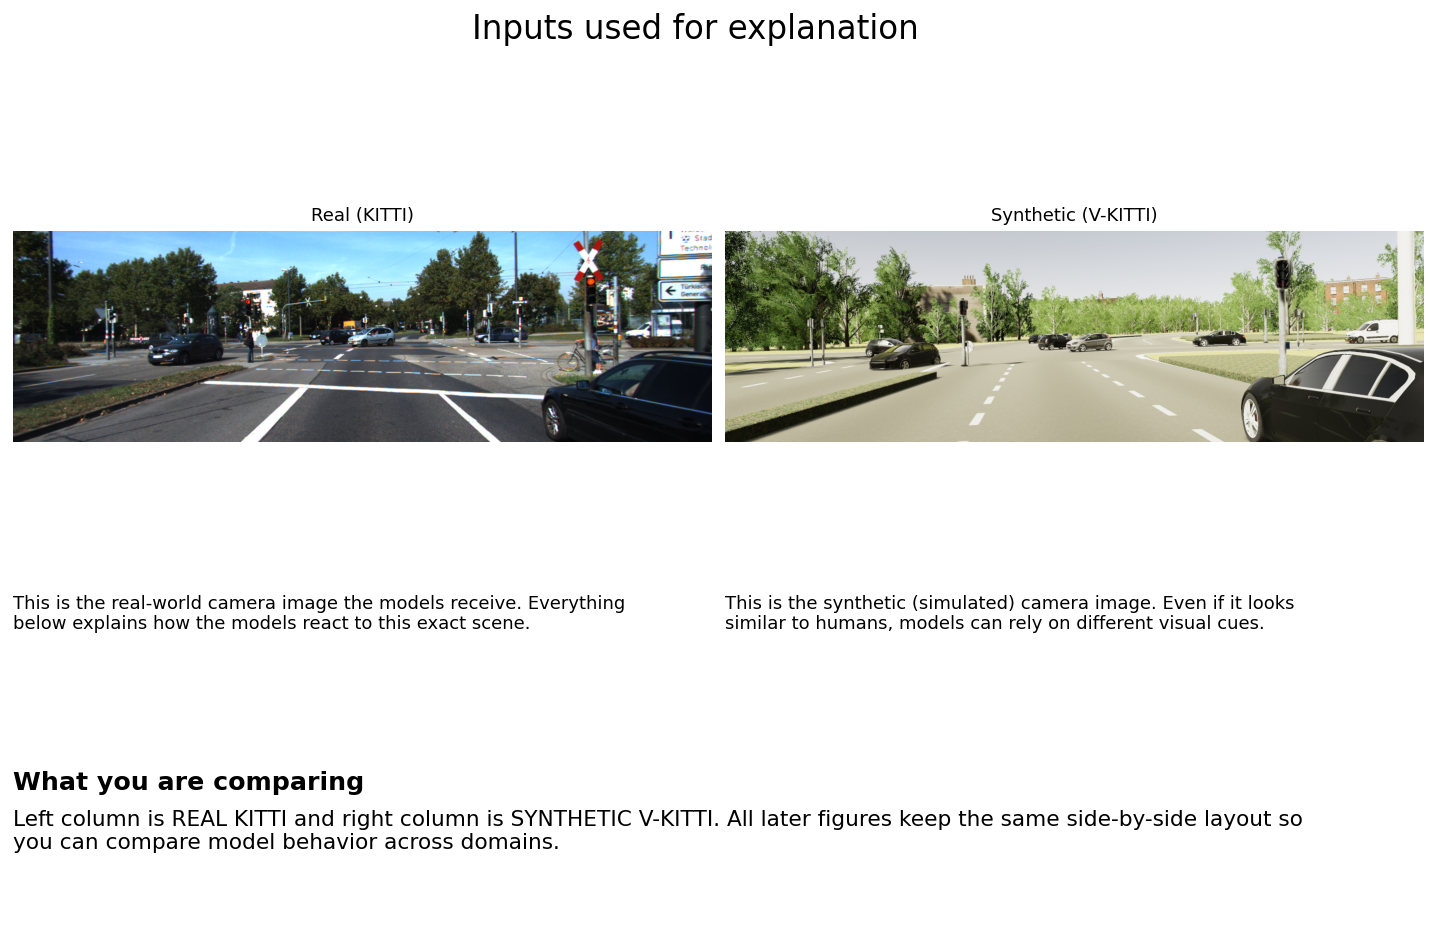

In [111]:
# --- Figure A: Input images (clean + readable) ---
# Structure: Row 1 = plots, Row 2 = plain-language description, Row 3 = legend/explanation

def _require_prep_vars():
    need = ["real_maps", "syn_maps", "real_path", "syn_path"]
    miss = [n for n in need if n not in globals()]
    if miss:
        raise RuntimeError("Missing prep variables: " + ", ".join(miss) + ". Run the prep cell first.")


_require_prep_vars()

fig = plt.figure(figsize=(14, 8), dpi=130)
gs = GridSpec(nrows=3, ncols=2, figure=fig, height_ratios=[1.0, 0.30, 0.35], hspace=0.15, wspace=0.02)

ax0 = fig.add_subplot(gs[0, 0]); ax1 = fig.add_subplot(gs[0, 1])
ax0.imshow(real_maps["img_rgb"]); ax0.axis("off"); ax0.set_title("Real (KITTI)", fontsize=10)
ax1.imshow(syn_maps["img_rgb"]);  ax1.axis("off"); ax1.set_title("Synthetic (V-KITTI)", fontsize=10)

d0 = fig.add_subplot(gs[1, 0]); d1 = fig.add_subplot(gs[1, 1])
_desc_axis(d0, "This is the real-world camera image the models receive. Everything below explains how the models react to this exact scene.", fontsize=10)
_desc_axis(d1, "This is the synthetic (simulated) camera image. Even if it looks similar to humans, models can rely on different visual cues.", fontsize=10)

l0 = fig.add_subplot(gs[2, :])
_legend_text_axis(
    l0,
    title="What you are comparing",
    body=(
        "Left column is REAL KITTI and right column is SYNTHETIC V-KITTI. "
        "All later figures keep the same side-by-side layout so you can compare model behavior across domains."
    ),
)

fig.suptitle("Inputs used for explanation", fontsize=18, y=0.98)
plt.show()

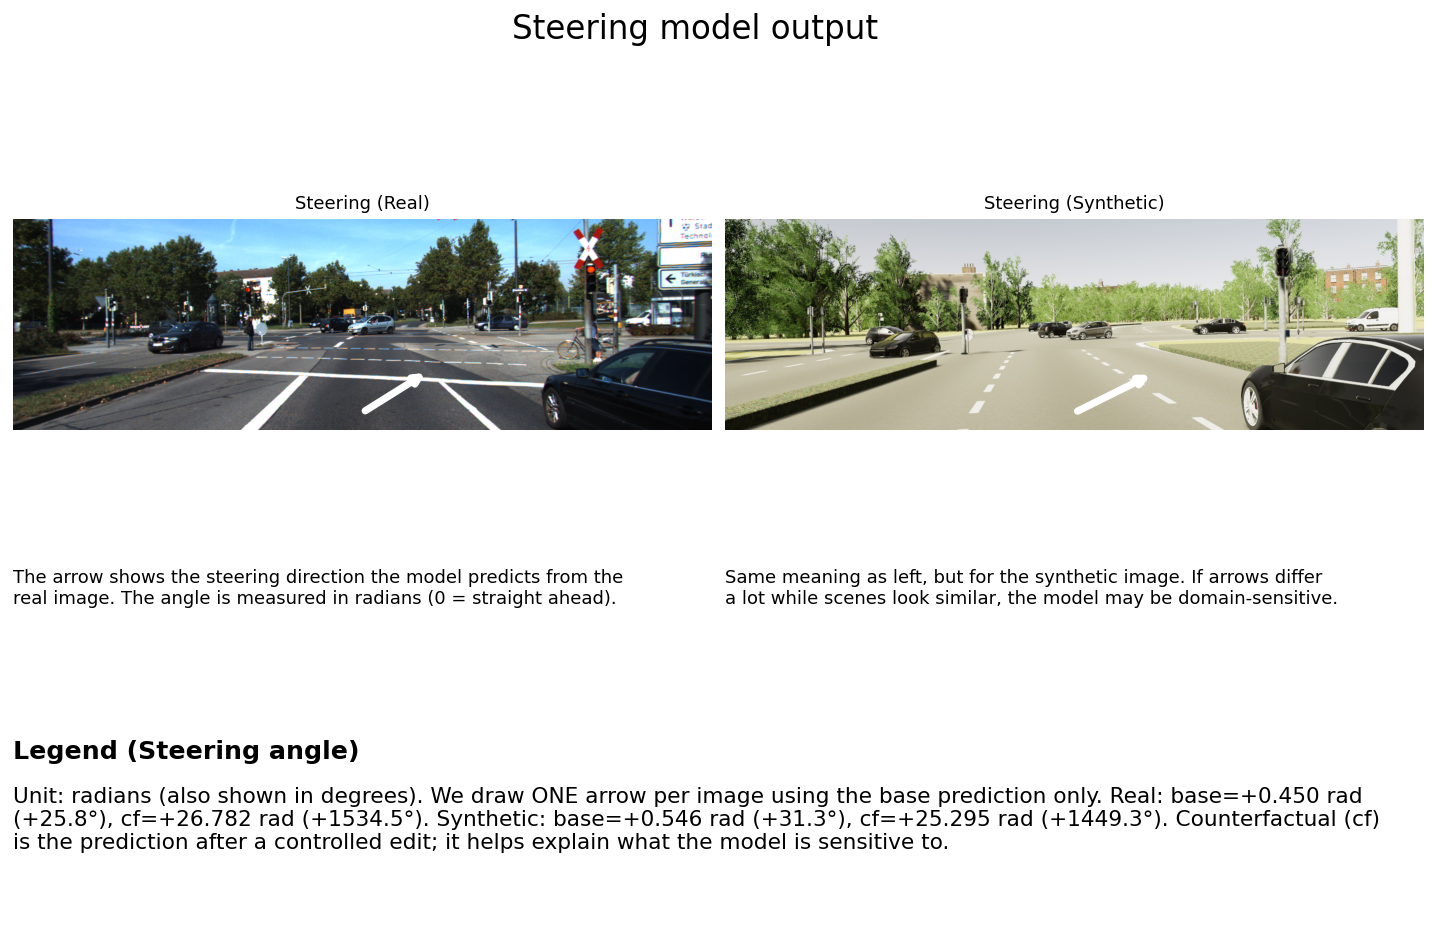

In [112]:
# --- Figure B: Steering output (arrow, radians) ---
# Requirement: show direction as an arrow indicating the predicted steering angle (radians).
# No text boxes on the image; all numbers/explanations go below in legend rows.

def _require_steering_vars():
    need = ["real_maps", "syn_maps", "real_payload", "syn_payload", "_draw_steering_arrow", "_rad_to_deg"]
    miss = [n for n in need if n not in globals()]
    if miss:
        raise RuntimeError("Missing prep variables: " + ", ".join(miss) + ". Run the prep cell first.")


_require_steering_vars()

r_base = float(real_payload["steering"]["base_pred"])
r_cf   = float(real_payload["steering"]["cf_pred"])
s_base = float(syn_payload["steering"]["base_pred"])
s_cf   = float(syn_payload["steering"]["cf_pred"])

fig = plt.figure(figsize=(14, 8), dpi=130)
gs = GridSpec(nrows=3, ncols=2, figure=fig, height_ratios=[1.0, 0.30, 0.45], hspace=0.15, wspace=0.02)

ax0 = fig.add_subplot(gs[0, 0]); ax1 = fig.add_subplot(gs[0, 1])
ax0.imshow(real_maps["img_rgb"]); ax0.axis("off"); ax0.set_title("Steering (Real)", fontsize=10)
ax1.imshow(syn_maps["img_rgb"]);  ax1.axis("off"); ax1.set_title("Steering (Synthetic)", fontsize=10)

# Arrow shows BASE prediction (what the model normally outputs on the scene).
_draw_steering_arrow(ax0, r_base)
_draw_steering_arrow(ax1, s_base)

d0 = fig.add_subplot(gs[1, 0]); d1 = fig.add_subplot(gs[1, 1])
_desc_axis(
    d0,
    "The arrow shows the steering direction the model predicts from the real image. The angle is measured in radians (0 = straight ahead).",
    fontsize=10,
)
_desc_axis(
    d1,
    "Same meaning as left, but for the synthetic image. If arrows differ a lot while scenes look similar, the model may be domain-sensitive.",
    fontsize=10,
)

l0 = fig.add_subplot(gs[2, :])
_legend_text_axis(
    l0,
    title="Legend (Steering angle)",
    body=(
        f"Unit: radians (also shown in degrees). We draw ONE arrow per image using the base prediction only. "
        f"Real: base={r_base:+.3f} rad ({_rad_to_deg(r_base):+.1f}°), cf={r_cf:+.3f} rad ({_rad_to_deg(r_cf):+.1f}°). "
        f"Synthetic: base={s_base:+.3f} rad ({_rad_to_deg(s_base):+.1f}°), cf={s_cf:+.3f} rad ({_rad_to_deg(s_cf):+.1f}°). "
        "Counterfactual (cf) is the prediction after a controlled edit; it helps explain what the model is sensitive to."
    ),
)

fig.suptitle("Steering model output", fontsize=18, y=0.98)
plt.show()

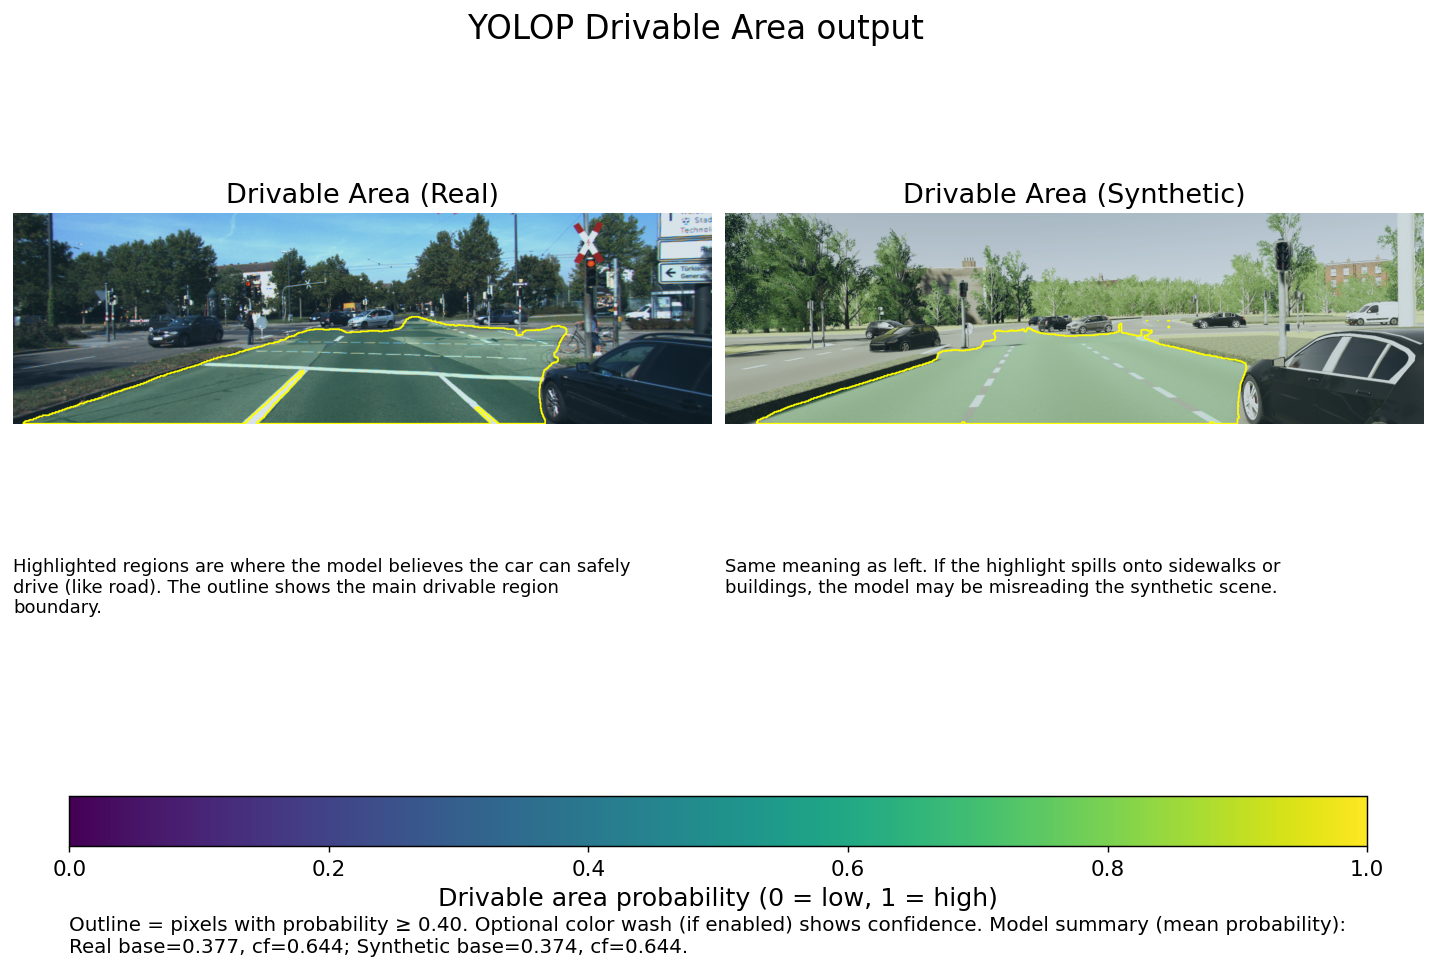

In [113]:
# --- Figure C: YOLOP Drivable Area (highlighted on image) ---
# Requirement: highlight the output area on the image (minimal clutter).
# Strategy: draw a clean outline of DA>=threshold, plus an optional faint adaptive heat overlay.

def _require_da_vars():
    need = ["real_maps", "syn_maps", "real_payload", "syn_payload", "_draw_outline_on_rgb", "_overlay_heat_adaptive", "PRESENT_DA_THR", "_legend_colorbar_axis"]
    miss = [n for n in need if n not in globals()]
    if miss:
        raise RuntimeError("Missing prep variables: " + ", ".join(miss) + ". Run the prep cell first.")


_require_da_vars()

# Toggle: set PRESENT_DA_SHOW_HEAT = False to draw outline only.
PRESENT_DA_SHOW_HEAT = bool(globals().get("PRESENT_DA_SHOW_HEAT", True))

def _da_viz(img_rgb: np.ndarray, da_prob: np.ndarray) -> np.ndarray:
    base = img_rgb
    if PRESENT_DA_SHOW_HEAT:
        base = _overlay_heat_adaptive(base, da_prob, cmap="viridis", base_alpha=0.35, gamma=0.6)
    # Outline in yellow-ish for readability
    return _draw_outline_on_rgb(base, da_prob, thr=PRESENT_DA_THR, color_bgr=(0, 255, 255), thickness=2)

r_base = float(real_payload["yolop_da"]["base_pred"])
r_cf   = float(real_payload["yolop_da"]["cf_pred"])
s_base = float(syn_payload["yolop_da"]["base_pred"])
s_cf   = float(syn_payload["yolop_da"]["cf_pred"])

real_img = _da_viz(real_maps["img_rgb"], real_maps["da_prob"])
syn_img  = _da_viz(syn_maps["img_rgb"],  syn_maps["da_prob"])

fig = plt.figure(figsize=(14, 8), dpi=130)
gs = GridSpec(nrows=3, ncols=2, figure=fig, height_ratios=[1.0, 0.30, 0.50], hspace=0.15, wspace=0.02)

ax0 = fig.add_subplot(gs[0, 0]); ax1 = fig.add_subplot(gs[0, 1])
ax0.imshow(real_img); ax0.axis("off"); ax0.set_title("Drivable Area (Real)", fontsize=15)
ax1.imshow(syn_img);  ax1.axis("off"); ax1.set_title("Drivable Area (Synthetic)", fontsize=15)

d0 = fig.add_subplot(gs[1, 0]); d1 = fig.add_subplot(gs[1, 1])
_desc_axis(d0, "Highlighted regions are where the model believes the car can safely drive (like road). The outline shows the main drivable region boundary.", fontsize=10)
_desc_axis(d1, "Same meaning as left. If the highlight spills onto sidewalks or buildings, the model may be misreading the synthetic scene.", fontsize=10)

l0 = fig.add_subplot(gs[2, :])
_legend_colorbar_axis(fig, l0, cmap="viridis", vmin=0.0, vmax=1.0, label="Drivable area probability (0 = low, 1 = high)")
l0.text(
    0.04, 0.01,
    textwrap.fill(
        f"Outline = pixels with probability ≥ {PRESENT_DA_THR:.2f}. "
        f"Optional color wash (if enabled) shows confidence. "
        f"Model summary (mean probability): Real base={r_base:.3f}, cf={r_cf:.3f}; Synthetic base={s_base:.3f}, cf={s_cf:.3f}.",
        width=130,
    ),
    transform=l0.transAxes,
    ha="left", va="top", fontsize=11,
)

fig.suptitle("YOLOP Drivable Area output", fontsize=18, y=0.98)
plt.show()

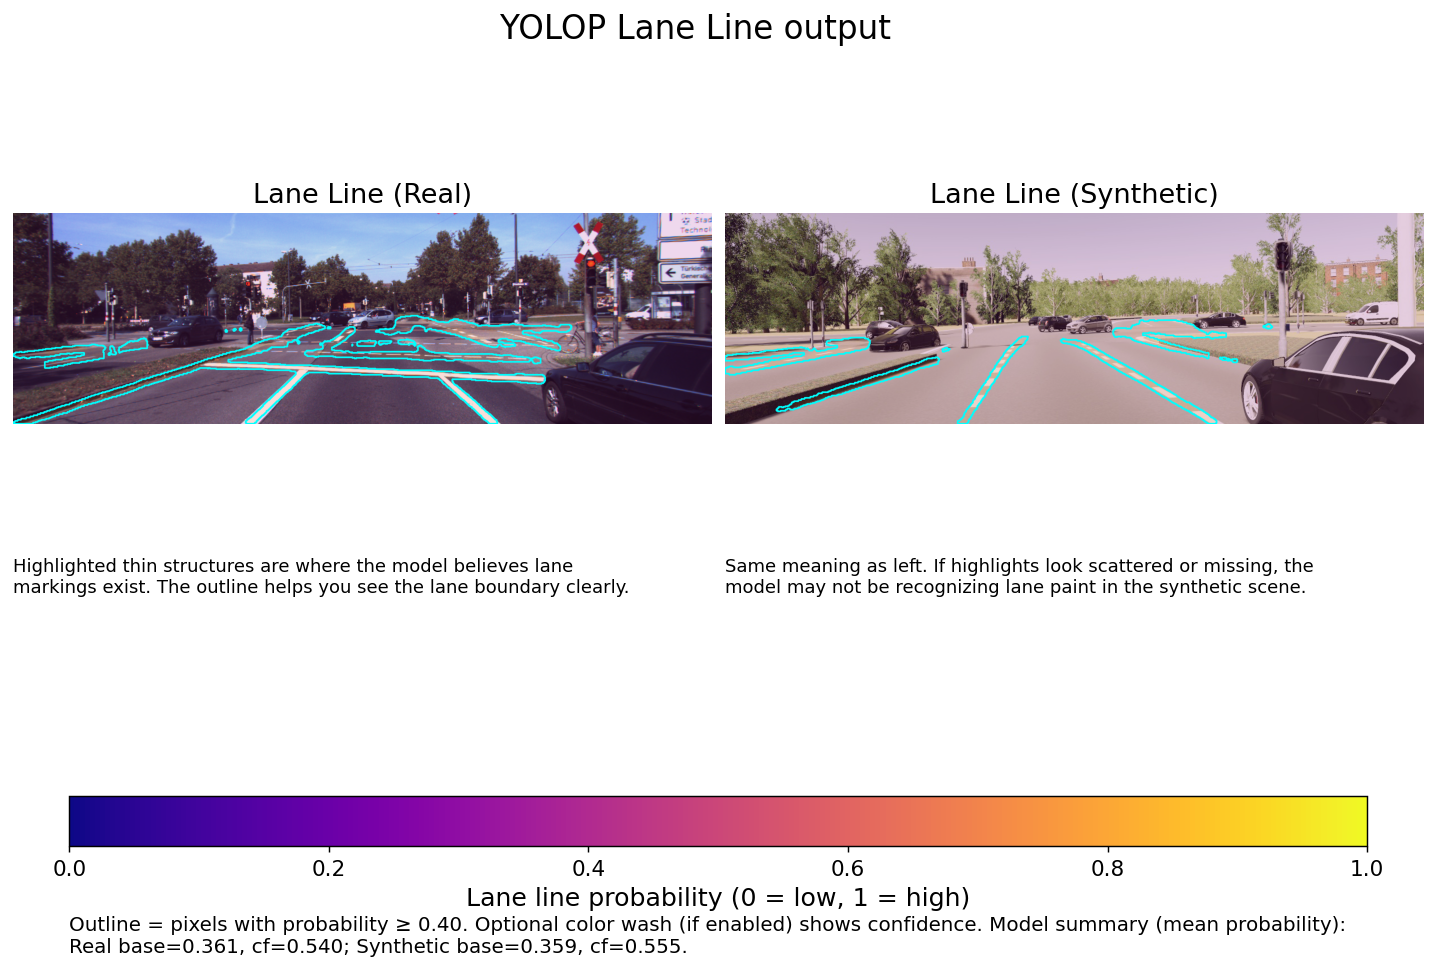

In [114]:
# --- Figure D: YOLOP Lane Line (highlighted on image) ---
# Requirement: highlight the output area on the image (minimal clutter).
# Strategy: draw lane boundaries (outline) + optional faint adaptive heat overlay.

def _require_ll_vars():
    need = ["real_maps", "syn_maps", "real_payload", "syn_payload", "_draw_outline_on_rgb", "_overlay_heat_adaptive", "PRESENT_LL_THR", "_legend_colorbar_axis"]
    miss = [n for n in need if n not in globals()]
    if miss:
        raise RuntimeError("Missing prep variables: " + ", ".join(miss) + ". Run the prep cell first.")


_require_ll_vars()

# Toggle: set PRESENT_LL_SHOW_HEAT = False to draw outline only.
PRESENT_LL_SHOW_HEAT = bool(globals().get("PRESENT_LL_SHOW_HEAT", True))

def _ll_viz(img_rgb: np.ndarray, ll_prob: np.ndarray) -> np.ndarray:
    base = img_rgb
    if PRESENT_LL_SHOW_HEAT:
        base = _overlay_heat_adaptive(base, ll_prob, cmap="plasma", base_alpha=0.30, gamma=0.55)
    # Outline in cyan-ish for readability
    return _draw_outline_on_rgb(base, ll_prob, thr=PRESENT_LL_THR, color_bgr=(255, 255, 0), thickness=2)

r_base = float(real_payload["yolop_ll"]["base_pred"])
r_cf   = float(real_payload["yolop_ll"]["cf_pred"])
s_base = float(syn_payload["yolop_ll"]["base_pred"])
s_cf   = float(syn_payload["yolop_ll"]["cf_pred"])

real_img = _ll_viz(real_maps["img_rgb"], real_maps["ll_prob"])
syn_img  = _ll_viz(syn_maps["img_rgb"],  syn_maps["ll_prob"])

fig = plt.figure(figsize=(14, 8), dpi=130)
gs = GridSpec(nrows=3, ncols=2, figure=fig, height_ratios=[1.0, 0.30, 0.50], hspace=0.15, wspace=0.02)

ax0 = fig.add_subplot(gs[0, 0]); ax1 = fig.add_subplot(gs[0, 1])
ax0.imshow(real_img); ax0.axis("off"); ax0.set_title("Lane Line (Real)", fontsize=15)
ax1.imshow(syn_img);  ax1.axis("off"); ax1.set_title("Lane Line (Synthetic)", fontsize=15)

d0 = fig.add_subplot(gs[1, 0]); d1 = fig.add_subplot(gs[1, 1])
_desc_axis(d0, "Highlighted thin structures are where the model believes lane markings exist. The outline helps you see the lane boundary clearly.", fontsize=10)
_desc_axis(d1, "Same meaning as left. If highlights look scattered or missing, the model may not be recognizing lane paint in the synthetic scene.", fontsize=10)

l0 = fig.add_subplot(gs[2, :])
_legend_colorbar_axis(fig, l0, cmap="plasma", vmin=0.0, vmax=1.0, label="Lane line probability (0 = low, 1 = high)")
l0.text(
    0.04, 0.01,
    textwrap.fill(
        f"Outline = pixels with probability ≥ {PRESENT_LL_THR:.2f}. "
        f"Optional color wash (if enabled) shows confidence. "
        f"Model summary (mean probability): Real base={r_base:.3f}, cf={r_cf:.3f}; Synthetic base={s_base:.3f}, cf={s_cf:.3f}.",
        width=130,
    ),
    transform=l0.transAxes,
    ha="left", va="top", fontsize=11,
)

fig.suptitle("YOLOP Lane Line output", fontsize=18, y=0.98)
plt.show()

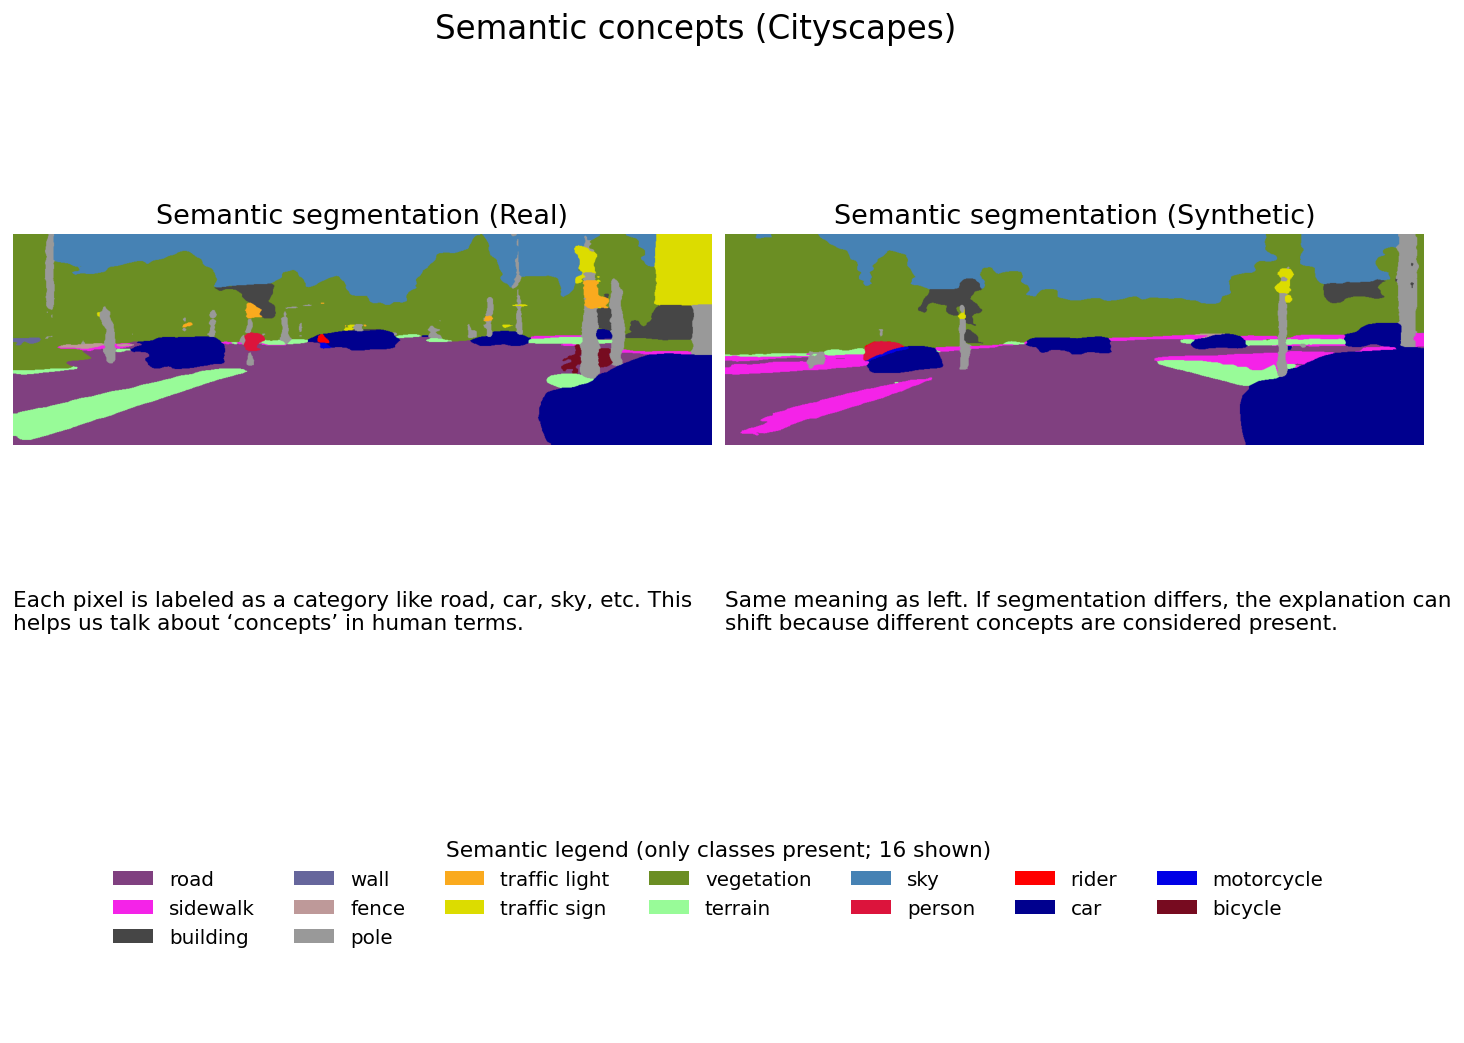

In [115]:
# --- Figure E: Semantic segmentation (readable legend; present classes only) ---
# Requirement: clean plot + separate description row + separate legend row.

def _require_seg_vars():
    need = ["real_maps", "syn_maps", "_legend_cityscapes_present_only"]
    miss = [n for n in need if n not in globals()]
    if miss:
        raise RuntimeError("Missing prep variables: " + ", ".join(miss) + ". Run the prep cell first.")


_require_seg_vars()

fig = plt.figure(figsize=(14, 9), dpi=130)
gs = GridSpec(nrows=3, ncols=2, figure=fig, height_ratios=[1.0, 0.30, 0.65], hspace=0.15, wspace=0.02)

ax0 = fig.add_subplot(gs[0, 0]); ax1 = fig.add_subplot(gs[0, 1])
ax0.imshow(real_maps["seg_rgb"]); ax0.axis("off"); ax0.set_title("Semantic segmentation (Real)", fontsize=15)
ax1.imshow(syn_maps["seg_rgb"]);  ax1.axis("off"); ax1.set_title("Semantic segmentation (Synthetic)", fontsize=15)

d0 = fig.add_subplot(gs[1, 0]); d1 = fig.add_subplot(gs[1, 1])
_desc_axis(d0, "Each pixel is labeled as a category like road, car, sky, etc. This helps us talk about ‘concepts’ in human terms.", fontsize=12)
_desc_axis(d1, "Same meaning as left. If segmentation differs, the explanation can shift because different concepts are considered present.", fontsize=12)

l0 = fig.add_subplot(gs[2, :])
_legend_cityscapes_present_only(l0, real_maps["seg_id"], syn_maps["seg_id"], max_cols=7)

fig.suptitle("Semantic concepts (Cityscapes)", fontsize=18, y=0.98)
plt.show()

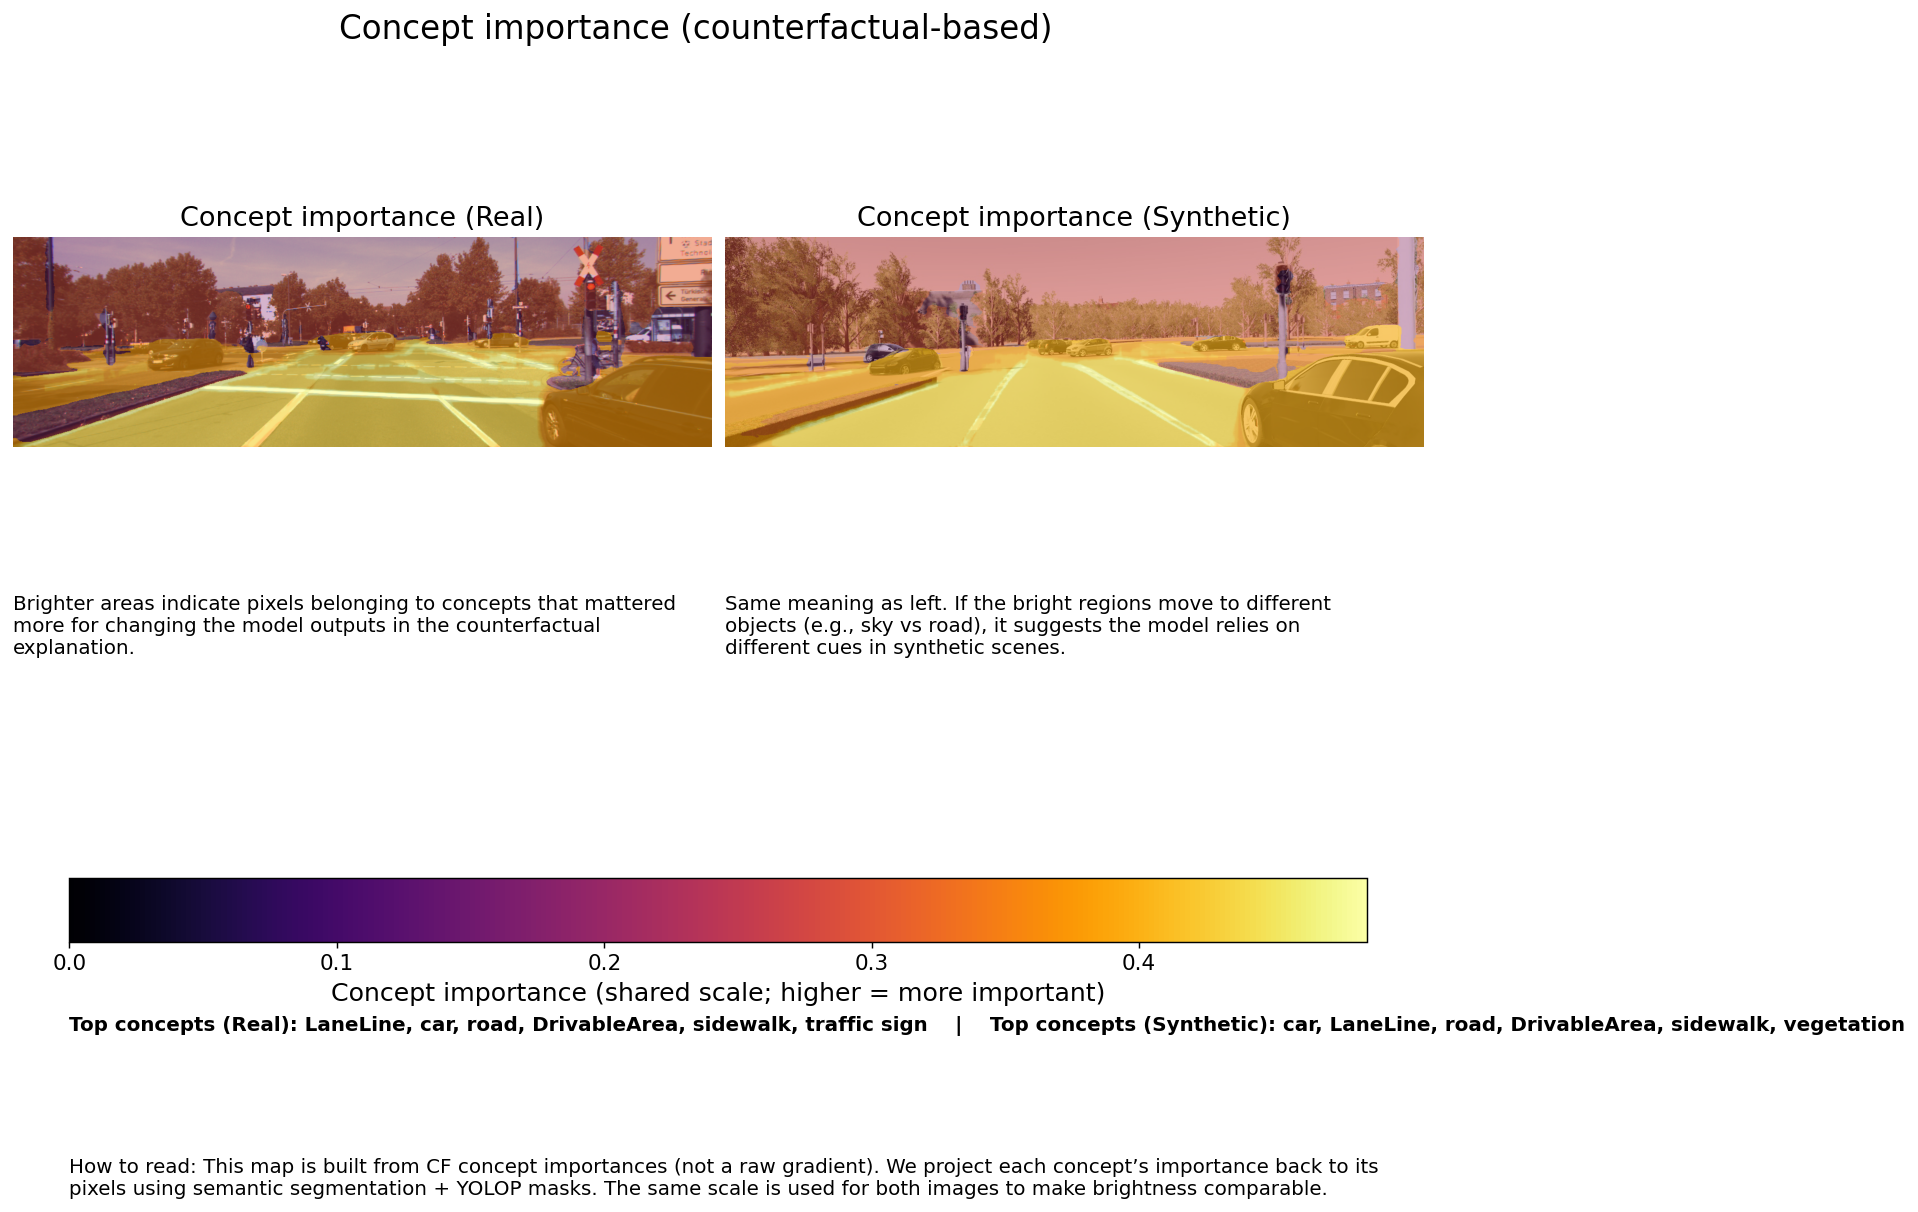

In [116]:
# --- Figure F: Concept importance (CF-based) — meticulous overlay + robust scaling ---
# Requirement: concept importance map is central and must be plotted meticulously.
# We use shared robust normalization (CONCEPT_VMAX) computed in the prep cell for fair Real vs Synthetic comparison.

def _require_concept_vars():
    need = [
        "real_maps", "syn_maps",
        "real_cmap", "syn_cmap",
        "real_cmap01", "syn_cmap01",
        "CONCEPT_VMAX",
        "real_cf_w", "syn_cf_w",
        "_overlay_heat_adaptive", "_legend_colorbar_axis", "_legend_text_axis", "_desc_axis",
    ]
    miss = [n for n in need if n not in globals()]
    if miss:
        raise RuntimeError("Missing prep variables: " + ", ".join(miss) + ". Run the prep cell first.")


_require_concept_vars()

# Overlay settings: strong enough to see, but adaptive alpha reduces clutter in low-importance areas.
real_img = _overlay_heat_adaptive(real_maps["img_rgb"], real_cmap01, cmap="inferno", base_alpha=0.72, gamma=0.75)
syn_img  = _overlay_heat_adaptive(syn_maps["img_rgb"],  syn_cmap01,  cmap="inferno", base_alpha=0.72, gamma=0.75)

fig = plt.figure(figsize=(14, 9), dpi=130)
gs = GridSpec(nrows=3, ncols=2, figure=fig, height_ratios=[1.0, 0.33, 0.60], hspace=0.15, wspace=0.02)

ax0 = fig.add_subplot(gs[0, 0]); ax1 = fig.add_subplot(gs[0, 1])
ax0.imshow(real_img); ax0.axis("off"); ax0.set_title("Concept importance (Real)", fontsize=15)
ax1.imshow(syn_img);  ax1.axis("off"); ax1.set_title("Concept importance (Synthetic)", fontsize=15)

d0 = fig.add_subplot(gs[1, 0]); d1 = fig.add_subplot(gs[1, 1])
_desc_axis(
    d0,
    "Brighter areas indicate pixels belonging to concepts that mattered more for changing the model outputs in the counterfactual explanation.",
    fontsize=11,
)
_desc_axis(
    d1,
    "Same meaning as left. If the bright regions move to different objects (e.g., sky vs road), it suggests the model relies on different cues in synthetic scenes.",
    fontsize=11,
)

def _topk(w: dict, k: int = 6):
    items = [(c, float(v)) for c, v in (w or {}).items() if float(v) > 0]
    items.sort(key=lambda x: x[1], reverse=True)
    return items[:k]

rt = _topk(real_cf_w, 6)
st = _topk(syn_cf_w, 6)
rt_s = ", ".join([c for c, _ in rt]) if rt else "(none)"
st_s = ", ".join([c for c, _ in st]) if st else "(none)"

l0 = fig.add_subplot(gs[2, :])
# Put a colorbar + compact explanation in the same legend row.
_legend_colorbar_axis(fig, l0, cmap="inferno", vmin=0.0, vmax=float(CONCEPT_VMAX), label="Concept importance (shared scale; higher = more important)")
# Add text over the same legend axis area, below the colorbar region.
l0.text(
    0.04, -0.5,
    textwrap.fill(
        "How to read: This map is built from CF concept importances (not a raw gradient). We project each concept’s importance back to its pixels using semantic segmentation + YOLOP masks. The same scale is used for both images to make brightness comparable.",
        width=130,
    ),
    transform=l0.transAxes,
    ha="left", va="top", fontsize=11,
)
l0.text(0.04, 0.06, f"Top concepts (Real): {rt_s}    |    Top concepts (Synthetic): {st_s}", transform=l0.transAxes, ha="left", va="top", fontsize=11, fontweight="bold")

fig.suptitle("Concept importance (counterfactual-based)", fontsize=18, y=0.98)
plt.show()

In [117]:
# --- Final: Ultra plain-language insights (non-technical, information-rich) ---
# This cell prints a narrative summary. It does NOT save files.

def _require_insight_vars():
    need = ["real_payload", "syn_payload", "real_cf_w", "syn_cf_w", "PRESENT_DA_THR", "PRESENT_LL_THR"]
    miss = [n for n in need if n not in globals()]
    if miss:
        raise RuntimeError("Missing variables: " + ", ".join(miss) + ". Run the prep cell first.")


_require_insight_vars()

def _topk(w: dict, k: int = 8):
    items = [(c, float(v)) for c, v in (w or {}).items() if float(v) > 0]
    items.sort(key=lambda x: x[1], reverse=True)
    return items[:k]

def _fmt_list(items):
    return ", ".join([c for c, _ in items]) if items else "(no strong concepts found)"

def _safe_float(x, default=0.0):
    try:
        return float(x)
    except Exception:
        return float(default)

r = real_payload
s = syn_payload

# Model outputs
r_steer_b = _safe_float(r["steering"]["base_pred"])
r_steer_c = _safe_float(r["steering"]["cf_pred"])
s_steer_b = _safe_float(s["steering"]["base_pred"])
s_steer_c = _safe_float(s["steering"]["cf_pred"])

r_da_b = _safe_float(r["yolop_da"]["base_pred"])
r_da_c = _safe_float(r["yolop_da"]["cf_pred"])
s_da_b = _safe_float(s["yolop_da"]["base_pred"])
s_da_c = _safe_float(s["yolop_da"]["cf_pred"])

r_ll_b = _safe_float(r["yolop_ll"]["base_pred"])
r_ll_c = _safe_float(r["yolop_ll"]["cf_pred"])
s_ll_b = _safe_float(s["yolop_ll"]["base_pred"])
s_ll_c = _safe_float(s["yolop_ll"]["cf_pred"])

# Top concepts
rt = _topk(real_cf_w, 8)
st = _topk(syn_cf_w, 8)

# Largest shifts (synthetic - real)
all_cs = set(real_cf_w) | set(syn_cf_w)
delta = {c: _safe_float(syn_cf_w.get(c, 0.0)) - _safe_float(real_cf_w.get(c, 0.0)) for c in all_cs}
big = sorted(delta.items(), key=lambda kv: abs(kv[1]), reverse=True)[:8]
big = [(c, d) for c, d in big if abs(d) > 1e-9]

print("\n==============================")
print("Plain-language explanation summary")
print("==============================\n")

print("1) What the models output")
print("- Steering (angle in radians):")
print(f"  - Real:      base {r_steer_b:+.3f} → counterfactual {r_steer_c:+.3f}")
print(f"  - Synthetic: base {s_steer_b:+.3f} → counterfactual {s_steer_c:+.3f}")
print("  How to read: 0 means straight. Positive/negative indicates turning direction.")
print("  (If arrows look reversed vs the road direction, flip the sign convention in the arrow helper.)\n")

print("- Drivable Area (average confidence):")
print(f"  - Real:      base {r_da_b:.3f} → counterfactual {r_da_c:.3f}")
print(f"  - Synthetic: base {s_da_b:.3f} → counterfactual {s_da_c:.3f}")
print(f"  We highlight pixels above {PRESENT_DA_THR:.2f} as the ‘drivable’ region outline.\n")

print("- Lane Line (average confidence):")
print(f"  - Real:      base {r_ll_b:.3f} → counterfactual {r_ll_c:.3f}")
print(f"  - Synthetic: base {s_ll_b:.3f} → counterfactual {s_ll_c:.3f}")
print(f"  We highlight pixels above {PRESENT_LL_THR:.2f} as lane-marking outline.\n")

print("2) What ‘concept importance’ means (in simple terms)")
print("- The system asks: ‘If we carefully change only specific semantic concepts (road, car, sky, lane line, drivable area…), which concepts most strongly change the model’s output?’")
print("- Brighter regions in the concept-importance map are not just ‘edges’ or ‘attention’; they are pixels belonging to concepts that mattered more in the counterfactual explanation.\n")

print("3) Key concepts the explanation relied on")
print("- Real top concepts:      " + _fmt_list(rt))
print("- Synthetic top concepts: " + _fmt_list(st))
print("  Interpretation: If these lists differ a lot, it suggests the model is using different cues in synthetic scenes, even when images look similar.\n")

print("4) Biggest changes from real → synthetic")
if big:
    for c, d in big[:6]:
        direction = "more important in synthetic" if d > 0 else "less important in synthetic"
        print(f"- {c}: {direction}")
else:
    print("- (No large shifts detected.)")
print()

print("5) Practical ‘risk flags’ (human-readable)")
flags = []
if abs(s_steer_b - r_steer_b) > 0.25:
    flags.append("Steering angle changes noticeably between real and synthetic.")
if s_da_b < r_da_b - 0.05:
    flags.append("Synthetic drivable-area confidence is lower than real.")
if s_ll_b < r_ll_b - 0.05:
    flags.append("Synthetic lane-line confidence is lower than real.")
if rt and st and rt[0][0] != st[0][0]:
    flags.append("Top explanation concept differs between real and synthetic.")
if flags:
    for f in flags:
        print("- " + f)
else:
    print("- No obvious red flags from these high-level checks.")

print("\n6) What to do next (non-technical)")
print("- If a ‘risk flag’ appears, inspect the matching figure: does the highlight land on the right physical region (road and lane markings)?")
print("- If the concept-importance map lights up on surprising objects (e.g., sky), that may indicate the model is using shortcuts instead of road cues.")
print("- Counterfactual results are explanations, not proof of causation — treat them as strong hints for where to investigate.")


Plain-language explanation summary

1) What the models output
- Steering (angle in radians):
  - Real:      base +0.450 → counterfactual +26.782
  - Synthetic: base +0.546 → counterfactual +25.295
  How to read: 0 means straight. Positive/negative indicates turning direction.
  (If arrows look reversed vs the road direction, flip the sign convention in the arrow helper.)

- Drivable Area (average confidence):
  - Real:      base 0.377 → counterfactual 0.644
  - Synthetic: base 0.374 → counterfactual 0.644
  We highlight pixels above 0.40 as the ‘drivable’ region outline.

- Lane Line (average confidence):
  - Real:      base 0.361 → counterfactual 0.540
  - Synthetic: base 0.359 → counterfactual 0.555
  We highlight pixels above 0.40 as lane-marking outline.

2) What ‘concept importance’ means (in simple terms)
- The system asks: ‘If we carefully change only specific semantic concepts (road, car, sky, lane line, drivable area…), which concepts most strongly change the model’s output?’

# Dataset-wide paired experiments (KITTI ↔ V-KITTI)



Goal: run paired experiments over many frames (e.g., 50 pairs) and summarize **scene/content demographics** plus **model/XAI** differences between real vs synthetic.



Ultra-critical notes:

- This is *paired* analysis: every V-KITTI sample must be derived from the chosen KITTI (seq, frame). Any unpaired sampling invalidates the comparisons.

- These runs are compute-heavy (counterfactual optimization + ablation per task). Start with N=10 to validate, then scale to N=50.

- “Demographics” here means content proxies (brightness/daylight proxy, segmentation composition, vehicles density, lane/DA coverage), not human identity attributes.


In [118]:
# # --- Batch config ---

# # Start small (e.g., 10) to sanity-check runtime/outputs, then increase.



# BATCH_N_PAIRS = int(globals().get("BATCH_N_PAIRS", 50))

# BATCH_SEED = int(globals().get("BATCH_SEED", 42))



# # If True, recompute everything; if False and a cache exists, it will be reused.

# BATCH_FORCE_RECOMPUTE = bool(globals().get("BATCH_FORCE_RECOMPUTE", False))



# # Save incremental results (recommended for long runs)

# BATCH_EXPORT_JSONL = globals().get("BATCH_EXPORT_JSONL", None)  # None => auto under analysis_exports/



# # Content-proxy thresholds (align with your presentation thresholds)

# BATCH_DA_THR = float(globals().get("BATCH_DA_THR", globals().get("PRESENT_DA_THR", getattr(CFG, "da_thresh", 0.4))))

# BATCH_LL_THR = float(globals().get("BATCH_LL_THR", globals().get("PRESENT_LL_THR", getattr(CFG, "lane_thresh", 0.4))))



# print("Batch config:")

# print("  N pairs:", BATCH_N_PAIRS)

# print("  Seed:", BATCH_SEED)

# print("  Force recompute:", BATCH_FORCE_RECOMPUTE)

# print("  DA thr / LL thr:", BATCH_DA_THR, BATCH_LL_THR)


In [119]:
# # --- Paired sampler (KITTI seq/frame → V-KITTI rgb_XXXXX.jpg) ---



# from pathlib import Path



# import numpy as np

# import pandas as pd



# # Keep mapping explicit and version-controlled in the notebook.

# _BATCH_KITTI_TO_VKITTI_SCENE = {

#     "0001": "scene_01",

#     "0002": "scene_02",

#     "0006": "scene_06",

#     "0018": "scene_18",

#     "0020": "scene_20",

# }





# def _batch_kitti_seq_frame_from_path(p: Path) -> tuple[str, int]:

#     p = Path(p)

#     try:

#         rel = p.resolve().relative_to(Path(CFG.kitti_root).resolve())

#         seq = rel.parts[0]

#         stem = Path(rel.parts[1]).stem

#     except Exception:

#         seq = p.parent.name

#         stem = p.stem

#     if not str(stem).isdigit():

#         raise ValueError(f"Cannot parse KITTI frame number from filename: {p.name}")

#     return str(seq), int(stem)





# def _batch_vkitti_rgb_for_kitti(seq: str, frame_num: int) -> Path:

#     if seq not in _BATCH_KITTI_TO_VKITTI_SCENE:

#         raise KeyError(f"No KITTI→V-KITTI scene mapping for KITTI sequence {seq!r}")

#     scene = _BATCH_KITTI_TO_VKITTI_SCENE[seq]

#     return Path(CFG.vkitti_root) / scene / "frames" / "rgb" / "Camera_0" / f"rgb_{frame_num:05d}.jpg"





# def _batch_list_pairable_kitti_images(kitti_root: Path) -> list[Path]:

#     exts = ("*.png", "*.jpg", "*.jpeg", "*.bmp")

#     out: list[Path] = []

#     for seq in sorted(_BATCH_KITTI_TO_VKITTI_SCENE.keys()):

#         seq_dir = Path(kitti_root) / seq

#         if not seq_dir.is_dir():

#             continue

#         for ext in exts:

#             out.extend(seq_dir.glob(ext))

#     out = sorted({p for p in out if p.is_file()}, key=lambda p: str(p).lower())

#     return out





# def sample_paired_frames(n_pairs: int, *, seed: int, stratify_by_seq: bool = True) -> pd.DataFrame:

#     """Sample paired frames.



#     Ultra-critical default: stratify by KITTI seq (when feasible) to avoid the random sampler

#     over-representing one scene/sequence and biasing the “domain shift” conclusions.

#     """



#     rng = np.random.default_rng(int(seed))

#     kitti_root = Path(CFG.kitti_root)

#     candidates = _batch_list_pairable_kitti_images(kitti_root)

#     if not candidates:

#         raise FileNotFoundError(f"No pairable KITTI images found under: {kitti_root}")



#     # Filter to those with existing paired V-KITTI.

#     pairs: list[dict] = []

#     dropped_missing_vkitti = 0

#     for p in candidates:

#         seq, fr = _batch_kitti_seq_frame_from_path(p)

#         vk = _batch_vkitti_rgb_for_kitti(seq, fr)

#         if not vk.exists():

#             dropped_missing_vkitti += 1

#             continue

#         pairs.append({

#             "seq": seq,

#             "frame": fr,

#             "real_path": str(p),

#             "syn_path": str(vk),

#         })



#     if not pairs:

#         raise RuntimeError("No valid paired frames found (all pairs missing V-KITTI rgb).")



#     df = pd.DataFrame(pairs)

#     df = df.sort_values(["seq", "frame"], kind="mergesort").reset_index(drop=True)



#     if n_pairs > len(df):

#         raise ValueError(f"Requested {n_pairs} pairs but only {len(df)} valid pairs exist.")



#     # Stratified sampling (preferred): equal counts per seq when possible.

#     if stratify_by_seq:

#         seqs = sorted(df["seq"].unique().tolist())

#         per_seq = n_pairs // len(seqs)

#         remainder = n_pairs % len(seqs)

#         ok = True

#         picks = []

#         for i, s in enumerate(seqs):

#             need = per_seq + (1 if i < remainder else 0)

#             pool = df[df["seq"] == s]

#             if need > len(pool):

#                 ok = False

#                 break

#             idx = rng.choice(len(pool), size=need, replace=False)

#             picks.append(pool.iloc[idx])

#         if ok:

#             df_s = pd.concat(picks, axis=0).sort_values(["seq", "frame"], kind="mergesort").reset_index(drop=True)

#         else:

#             print("WARNING: stratified sampling not feasible (a seq has too few frames). Falling back to global random.")

#             idx = rng.choice(len(df), size=int(n_pairs), replace=False)

#             df_s = df.iloc[idx].sort_values(["seq", "frame"], kind="mergesort").reset_index(drop=True)

#     else:

#         idx = rng.choice(len(df), size=int(n_pairs), replace=False)

#         df_s = df.iloc[idx].sort_values(["seq", "frame"], kind="mergesort").reset_index(drop=True)



#     print("Sampler QC:")

#     print("  Candidate KITTI frames:", len(candidates))

#     print("  Dropped (missing paired V-KITTI rgb):", dropped_missing_vkitti)

#     print("  Valid pairs:", len(df))

#     print("  Sampled pairs:", len(df_s))

#     print("  Stratified by seq:", bool(stratify_by_seq))

#     print("  Seq distribution:\n", df_s["seq"].value_counts().sort_index().to_string())

#     return df_s





# df_pairs = sample_paired_frames(BATCH_N_PAIRS, seed=BATCH_SEED, stratify_by_seq=True)

# df_pairs.head(10)


In [120]:
# # --- Batch runner: compute content demographics + model/XAI metrics ---



# import json

# import time

# from datetime import datetime

# from pathlib import Path



# import numpy as np

# import pandas as pd



# try:

#     from tqdm.auto import tqdm

# except Exception:

#     tqdm = None





# def _require_for_batch():

#     need = [

#         "CFG",

#         "run_single_image",

#         "load_pil",

#         "mask2former_cityscapes_seg",

#         "yolop_predict_masks",

#         "CITYSCAPES_ID_TO_NAME",

#         "CITYSCAPES_NAME_TO_ID",

#     ]

#     miss = [n for n in need if n not in globals()]

#     if miss:

#         raise RuntimeError(

#             "Missing required globals for batch run: " + ", ".join(miss) + ". Run the setup/pipeline cells above first."

#         )





# def _to_rgb_u8(img_pil):

#     arr = np.array(img_pil.convert("RGB"), dtype=np.uint8)

#     if arr.ndim != 3 or arr.shape[2] != 3:

#         raise ValueError(f"Expected RGB image; got {arr.shape}")

#     return arr





# def _resize_to_hw(arr: np.ndarray, hw, *, mode: str) -> np.ndarray:

#     import cv2



#     h, w = int(hw[0]), int(hw[1])

#     if arr.shape[0] == h and arr.shape[1] == w:

#         return arr

#     interp = cv2.INTER_LINEAR if mode == "linear" else cv2.INTER_NEAREST

#     return cv2.resize(arr, (w, h), interpolation=interp)





# def _compute_pixel_maps(img_path: Path) -> dict:

#     img_pil = load_pil(img_path)

#     img_rgb = _to_rgb_u8(img_pil)

#     seg_id = mask2former_cityscapes_seg(img_pil)

#     yolop_masks = yolop_predict_masks(img_pil)

#     da_raw = yolop_masks["da_raw"].astype(np.float32)

#     ll_raw = yolop_masks["ll_raw"].astype(np.float32)



#     h, w = img_rgb.shape[:2]

#     if seg_id.shape != (h, w):

#         seg_id = _resize_to_hw(seg_id.astype(np.int32), (h, w), mode="nearest")

#     if da_raw.shape != (h, w):

#         da_raw = _resize_to_hw(da_raw, (h, w), mode="linear")

#     if ll_raw.shape != (h, w):

#         ll_raw = _resize_to_hw(ll_raw, (h, w), mode="linear")



#     return {

#         "img_rgb": img_rgb,

#         "seg_id": seg_id.astype(np.int32),

#         "da_prob": np.clip(da_raw, 0.0, 1.0),

#         "ll_prob": np.clip(ll_raw, 0.0, 1.0),

#     }





# def _aggregate_cf_weights(domain_payload: dict, *, min_cov: float = 0.003) -> dict[str, float]:

#     weights: dict[str, list[float]] = {}

#     covs: dict[str, list[float]] = {}

#     for task in ("steering", "yolop_da", "yolop_ll"):

#         concepts = domain_payload[task].get("cf_concepts", {})

#         for concept, (imp, cov) in concepts.items():

#             weights.setdefault(concept, []).append(float(imp))

#             covs.setdefault(concept, []).append(float(cov))

#     out: dict[str, float] = {}

#     for concept, imps in weights.items():

#         mean_cov = float(np.mean(covs.get(concept, [0.0])))

#         out[concept] = 0.0 if mean_cov < float(min_cov) else float(np.mean(imps))

#     return out





# def _concept_map_fast(

#     seg_id_hw: np.ndarray, da_prob_hw: np.ndarray, ll_prob_hw: np.ndarray, cf_weights: dict[str, float]

# ) -> np.ndarray:

#     # Vectorized reconstruction of the same semantics as _concept_map in the presentation cell.

#     h, w = seg_id_hw.shape

#     m = np.zeros((h, w), dtype=np.float32)



#     # Cityscapes class weights as lookup table.

#     w_by_id = np.zeros((19,), dtype=np.float32)

#     for name, cid in CITYSCAPES_NAME_TO_ID.items():

#         if 0 <= int(cid) < 19:

#             w_by_id[int(cid)] = float(cf_weights.get(name, 0.0))

#     m += w_by_id[np.clip(seg_id_hw, 0, 18)]



#     # Probabilistic concepts.

#     w_da = float(cf_weights.get("DrivableArea", 0.0))

#     w_ll = float(cf_weights.get("LaneLine", 0.0))

#     if w_da > 0:

#         m += w_da * da_prob_hw.astype(np.float32)

#     if w_ll > 0:

#         m += w_ll * ll_prob_hw.astype(np.float32)

#     return m





# def _luma_stats(img_rgb_u8: np.ndarray) -> tuple[float, float]:

#     # Daylight proxy: mean & std of luminance (0..1). Extremely crude but monotonic.

#     x = img_rgb_u8.astype(np.float32) / 255.0

#     y = 0.2126 * x[..., 0] + 0.7152 * x[..., 1] + 0.0722 * x[..., 2]

#     return float(y.mean()), float(y.std())





# def _seg_fraction(seg_id_hw: np.ndarray, name: str) -> float:

#     cid = CITYSCAPES_NAME_TO_ID.get(name, None)

#     if cid is None:

#         return 0.0

#     return float((seg_id_hw == int(cid)).mean())





# def _make_export_path() -> Path:

#     if BATCH_EXPORT_JSONL:

#         return Path(BATCH_EXPORT_JSONL)

#     ts = datetime.now().strftime("%Y%m%d_%H%M%S")

#     out_dir = Path(getattr(CFG, "export_dir", "analysis_exports"))

#     out_dir.mkdir(parents=True, exist_ok=True)

#     return out_dir / f"batch_pairs_{BATCH_N_PAIRS}_seed{BATCH_SEED}_{ts}.jsonl"





# _require_for_batch()



# export_path = _make_export_path()

# print("Export path:", export_path)



# # If cache exists and not forcing recompute, load it.

# cache_rows = []

# if export_path.exists() and not BATCH_FORCE_RECOMPUTE:

#     with export_path.open("r", encoding="utf-8") as f:

#         for line in f:

#             line = line.strip()

#             if not line:

#                 continue

#             cache_rows.append(json.loads(line))

#     print(f"Loaded cache rows: {len(cache_rows)}")



# cache_by_key = {

#     (r.get("domain"), r.get("real_path"), r.get("syn_path"), r.get("which")): r

#     for r in cache_rows

#     if isinstance(r, dict)

# }



# rows_img = []

# rows_task = []

# rows_cfconcept = []

# rows_contrib = []

# sampled_cmap_values = []



# pairs_iter = df_pairs.to_dict(orient="records")

# it = tqdm(pairs_iter, desc="Pairs", total=len(pairs_iter)) if tqdm else pairs_iter



# t0 = time.time()

# n_done = 0

# with export_path.open("a", encoding="utf-8") as f_out:

#     for pair in it:

#         real_p = Path(pair["real_path"])

#         syn_p = Path(pair["syn_path"])



#         for domain, p in (("real", real_p), ("syn", syn_p)):

#             key = (domain, str(real_p), str(syn_p), str(p))

#             cached = cache_by_key.get(key, None)

#             if cached is not None and not BATCH_FORCE_RECOMPUTE:

#                 rows_img.append(cached["img_row"])

#                 rows_task.extend(cached["task_rows"])

#                 rows_cfconcept.extend(cached["cfconcept_rows"])

#                 rows_contrib.extend(cached["contrib_rows"])

#                 sampled_cmap_values.extend(cached.get("cmap_samples", []))

#                 continue



#             payload = run_single_image(p)

#             maps = _compute_pixel_maps(p)

#             seg_id = maps["seg_id"]

#             da_prob = maps["da_prob"]

#             ll_prob = maps["ll_prob"]

#             img_rgb = maps["img_rgb"]



#             # Content demographics

#             lum_mean, lum_std = _luma_stats(img_rgb)

#             sky_frac = _seg_fraction(seg_id, "Sky")

#             road_frac = _seg_fraction(seg_id, "Road")

#             veg_frac = _seg_fraction(seg_id, "Vegetation")

#             building_frac = _seg_fraction(seg_id, "Building")



#             vehicle_frac = sum(_seg_fraction(seg_id, n) for n in ("Car", "Truck", "Bus", "Motorcycle", "Bicycle"))

#             human_frac = sum(_seg_fraction(seg_id, n) for n in ("Person", "Rider"))



#             da_area = float((da_prob >= float(BATCH_DA_THR)).mean())

#             ll_area = float((ll_prob >= float(BATCH_LL_THR)).mean())



#             # Concept-importance (pixel map) samples for robust shared scaling

#             cf_w = _aggregate_cf_weights(payload)

#             cmap = _concept_map_fast(seg_id, da_prob, ll_prob, cf_w)

#             # sample up to 5000 pixels per image (for global scale estimation)

#             h, w = cmap.shape

#             n_samp = min(5000, h * w)

#             rng = np.random.default_rng((hash(str(p)) ^ (BATCH_SEED + 1337)) & 0xFFFFFFFF)

#             flat_idx = rng.choice(h * w, size=n_samp, replace=False)

#             samp = cmap.reshape(-1)[flat_idx].astype(np.float32)

#             sampled_cmap_values.extend(samp.tolist())



#             img_row = {

#                 "domain": domain,

#                 "seq": pair["seq"],

#                 "frame": int(pair["frame"]),

#                 "real_path": str(real_p),

#                 "syn_path": str(syn_p),

#                 "which": str(p),

#                 "lum_mean": lum_mean,

#                 "lum_std": lum_std,

#                 "sky_frac": sky_frac,

#                 "road_frac": road_frac,

#                 "veg_frac": veg_frac,

#                 "building_frac": building_frac,

#                 "vehicle_frac": float(vehicle_frac),

#                 "human_frac": float(human_frac),

#                 "da_area": da_area,

#                 "ll_area": ll_area,

#                 "cmap_mean_raw": float(cmap.mean()),

#                 "cmap_p95_raw": float(np.percentile(cmap, 95.0)),

#                 "cmap_max_raw": float(np.max(cmap)),

#             }

#             rows_img.append(img_row)



#             # Per-task prediction summaries

#             task_rows = []

#             for task_name in ("steering", "yolop_da", "yolop_ll"):

#                 t = payload[task_name]

#                 base = float(t.get("base_pred", np.nan))

#                 cf = float(t.get("cf_pred", np.nan))

#                 task_rows.append(

#                     {

#                         "domain": domain,

#                         "seq": pair["seq"],

#                         "frame": int(pair["frame"]),

#                         "task": task_name,

#                         "base_pred": base,

#                         "cf_pred": cf,

#                         "delta_cf": cf - base,

#                         "cf_edit_mask_sum": float(t.get("cf_edit_mask_sum", np.nan)),

#                     }

#                 )

#             rows_task.extend(task_rows)



#             # CF concept table from payload (what CF saliency aggregator says)

#             cfconcept_rows = []

#             for task_name in ("steering", "yolop_da", "yolop_ll"):

#                 concepts = payload[task_name].get("cf_concepts", {})

#                 for concept, (imp, cov) in concepts.items():

#                     cfconcept_rows.append(

#                         {

#                             "domain": domain,

#                             "seq": pair["seq"],

#                             "frame": int(pair["frame"]),

#                             "task": task_name,

#                             "concept": str(concept),

#                             "imp": float(imp),

#                             "cov": float(cov),

#                         }

#                     )

#             rows_cfconcept.extend(cfconcept_rows)



#             # Concept contribution breakdown (from cf_w + scene masks)

#             contrib_rows = []

#             # Cityscapes classes

#             for name in (

#                 "Road",

#                 "Sky",

#                 "Vegetation",

#                 "Building",

#                 "Sidewalk",

#                 "Car",

#                 "Truck",

#                 "Bus",

#                 "TrafficLight",

#                 "TrafficSign",

#             ):

#                 wgt = float(cf_w.get(name, 0.0))

#                 cov = _seg_fraction(seg_id, name)

#                 contrib_rows.append(

#                     {

#                         "domain": domain,

#                         "seq": pair["seq"],

#                         "frame": int(pair["frame"]),

#                         "concept": name,

#                         "weight": wgt,

#                         "coverage": cov,

#                         "mean_importance_within_raw": wgt,

#                         "mean_contribution_global_raw": wgt * cov,

#                     }

#                 )

#             # Probabilistic concepts

#             for name, prob, thr in (

#                 ("DrivableArea", da_prob, float(BATCH_DA_THR)),

#                 ("LaneLine", ll_prob, float(BATCH_LL_THR)),

#             ):

#                 wgt = float(cf_w.get(name, 0.0))

#                 mask = prob >= thr

#                 cov = float(mask.mean())

#                 mean_within = float((wgt * prob[mask].mean()) if mask.any() else 0.0)

#                 mean_global = float(wgt * prob.mean())

#                 contrib_rows.append(

#                     {

#                         "domain": domain,

#                         "seq": pair["seq"],

#                         "frame": int(pair["frame"]),

#                         "concept": name,

#                         "weight": wgt,

#                         "coverage": cov,

#                         "mean_importance_within_raw": mean_within,

#                         "mean_contribution_global_raw": mean_global,

#                     }

#                 )

#             rows_contrib.extend(contrib_rows)



#             # Write a compact cache record per image (so long runs can resume safely)

#             cache_rec = {

#                 "domain": domain,

#                 "real_path": str(real_p),

#                 "syn_path": str(syn_p),

#                 "which": str(p),

#                 "img_row": img_row,

#                 "task_rows": task_rows,

#                 "cfconcept_rows": cfconcept_rows,

#                 "contrib_rows": contrib_rows,

#                 "cmap_samples": samp.tolist(),

#             }

#             f_out.write(json.dumps(cache_rec) + "\n")

#             f_out.flush()



#         n_done += 1

#         if tqdm is None and (n_done % 5 == 0):

#             dt = time.time() - t0

#             print(f"Processed {n_done}/{len(pairs_iter)} pairs in {dt:.1f}s")



# dt = time.time() - t0

# print(f"Batch finished: {len(pairs_iter)} pairs in {dt/60.0:.1f} min")



# # Build dataframes

# df_img = pd.DataFrame(rows_img)

# df_task = pd.DataFrame(rows_task)

# df_cfconcept = pd.DataFrame(rows_cfconcept)

# df_contrib = pd.DataFrame(rows_contrib)



# print("Shapes:")

# print("  df_pairs:", df_pairs.shape)

# print("  df_img:", df_img.shape)

# print("  df_task:", df_task.shape)

# print("  df_cfconcept:", df_cfconcept.shape)

# print("  df_contrib:", df_contrib.shape)


In [121]:
# # --- QC + robust normalization for concept-importance ---



# import numpy as np

# import pandas as pd



# if len(sampled_cmap_values) == 0:

#     raise RuntimeError("No concept-map samples collected; did the batch run?")



# _s = np.asarray(sampled_cmap_values, dtype=np.float32)

# CONCEPT_VMAX_DATASET = float(np.percentile(_s, 99.0))

# if not np.isfinite(CONCEPT_VMAX_DATASET) or CONCEPT_VMAX_DATASET <= 1e-12:

#     CONCEPT_VMAX_DATASET = float(np.max(_s)) if _s.size else 1.0

# CONCEPT_VMAX_DATASET = max(CONCEPT_VMAX_DATASET, 1.0)



# print("Robust dataset concept vmax (p99; clamped>=1):", CONCEPT_VMAX_DATASET)



# # Normalize select columns so comparisons are on a shared scale

# df_img = df_img.copy()

# for col in ("cmap_mean_raw", "cmap_p95_raw", "cmap_max_raw"):

#     df_img[col.replace("_raw", "_norm")] = np.clip(df_img[col] / float(CONCEPT_VMAX_DATASET), 0.0, 1.0)



# df_contrib = df_contrib.copy()

# df_contrib["mean_importance_within_norm"] = np.clip(

#     df_contrib["mean_importance_within_raw"] / float(CONCEPT_VMAX_DATASET), 0.0, 1.0

# )

# df_contrib["mean_contribution_global_norm"] = np.clip(

#     df_contrib["mean_contribution_global_raw"] / float(CONCEPT_VMAX_DATASET), 0.0, 1.0

# )



# # Pair-level joins for paired deltas (syn - real)

# def _paired_delta(df: pd.DataFrame, value_col: str, *, key_cols=("seq", "frame")) -> pd.DataFrame:

#     a = df[df["domain"] == "real"].set_index(list(key_cols))[[value_col]].rename(columns={value_col: "real"})

#     b = df[df["domain"] == "syn"].set_index(list(key_cols))[[value_col]].rename(columns={value_col: "syn"})

#     out = a.join(b, how="inner")

#     out["delta_syn_minus_real"] = out["syn"] - out["real"]

#     return out.reset_index()



# # Quick pairing sanity: all seq/frame must have both domains

# _check = df_img.groupby(["seq", "frame"])["domain"].nunique().value_counts().sort_index()

# print("QC: domain count per pair (should be all 2):\n", _check.to_string())



# display(df_img.head(5))

# display(df_task.head(5))

# display(df_contrib.head(5))


In [122]:
# # --- Plots: demographics + model differences (paired) ---



# import numpy as np

# import pandas as pd

# import matplotlib.pyplot as plt



# try:

#     import seaborn as sns

# except Exception:

#     sns = None



# # 1) Model outputs: distributions and paired deltas

# fig = plt.figure(figsize=(14, 9), dpi=130)

# gs = fig.add_gridspec(nrows=2, ncols=3, hspace=0.35, wspace=0.25)



# tasks = ["steering", "yolop_da", "yolop_ll"]

# for j, task_name in enumerate(tasks):

#     ax = fig.add_subplot(gs[0, j])

#     d = df_task[df_task["task"] == task_name]

#     if sns:

#         sns.violinplot(data=d, x="domain", y="base_pred", ax=ax, inner="quartile", cut=0)

#     else:

#         ax.boxplot([d[d["domain"]=="real"]["base_pred"].dropna(), d[d["domain"]=="syn"]["base_pred"].dropna()], labels=["real","syn"])

#     ax.set_title(f"{task_name}: base_pred (real vs syn)")

#     ax.set_xlabel("")



#     ax2 = fig.add_subplot(gs[1, j])

#     dd = _paired_delta(d, "base_pred")

#     if sns:

#         sns.histplot(dd["delta_syn_minus_real"], bins=20, kde=True, ax=ax2)

#     else:

#         ax2.hist(dd["delta_syn_minus_real"].dropna(), bins=20)

#     ax2.axvline(0.0, color="black", lw=1)

#     ax2.set_title(f"{task_name}: delta base (syn - real)")

#     ax2.set_xlabel("Δ")



# fig.suptitle("Model outputs across paired frames", y=0.98, fontsize=14)

# plt.show()



# # 2) Content demographics (proxies) real vs syn

# fig = plt.figure(figsize=(14, 7), dpi=130)

# gs = fig.add_gridspec(nrows=1, ncols=3, wspace=0.25)



# ax0 = fig.add_subplot(gs[0, 0])

# if sns:

#     sns.violinplot(data=df_img, x="domain", y="lum_mean", ax=ax0, inner="quartile", cut=0)

# else:

#     ax0.boxplot([df_img[df_img["domain"]=="real"]["lum_mean"], df_img[df_img["domain"]=="syn"]["lum_mean"]], labels=["real","syn"])

# ax0.set_title("Daylight proxy: luminance mean")

# ax0.set_xlabel("")



# ax1 = fig.add_subplot(gs[0, 1])

# cols = ["road_frac", "sky_frac", "veg_frac", "vehicle_frac"]

# d_m = df_img.groupby("domain")[cols].mean().T

# d_m.plot(kind="bar", ax=ax1)

# ax1.set_title("Mean segmentation composition (proxy)")

# ax1.set_ylabel("fraction of pixels")

# ax1.legend(title="domain")



# ax2 = fig.add_subplot(gs[0, 2])

# dd = _paired_delta(df_img, "cmap_p95_norm")

# if sns:

#     sns.histplot(dd["delta_syn_minus_real"], bins=20, kde=True, ax=ax2)

# else:

#     ax2.hist(dd["delta_syn_minus_real"].dropna(), bins=20)

# ax2.axvline(0.0, color="black", lw=1)

# ax2.set_title("Concept-importance intensity: p95 (norm) Δ(syn-real)")

# ax2.set_xlabel("Δ")



# fig.suptitle("Scene/content demographics + XAI intensity", y=0.98, fontsize=14)

# plt.show()


In [123]:
# # --- Plot: which concepts drive domain deltas? (paired, corrected) ---



# import numpy as np

# import pandas as pd

# import matplotlib.pyplot as plt



# try:

#     from scipy.stats import wilcoxon

# except Exception:

#     wilcoxon = None





# def _bh_fdr(pvals: np.ndarray) -> np.ndarray:

#     # Benjamini–Hochberg FDR, returns adjusted q-values.

#     p = np.asarray(pvals, dtype=float)

#     n = p.size

#     order = np.argsort(p)

#     ranked = p[order]

#     q = ranked * n / (np.arange(n) + 1)

#     q = np.minimum.accumulate(q[::-1])[::-1]

#     out = np.empty_like(q)

#     out[order] = np.clip(q, 0.0, 1.0)

#     return out





# # Build paired deltas for concept global contribution (normalized)

# dc = df_contrib.pivot_table(

#     index=["seq", "frame", "concept"],

#     columns="domain",

#     values="mean_contribution_global_norm",

#     aggfunc="mean",

# ).reset_index()



# if "real" not in dc.columns or "syn" not in dc.columns:

#     raise RuntimeError("Missing real/syn columns after pivot; check pairing/QC.")



# dc["delta"] = dc["syn"] - dc["real"]



# # Rank concepts by mean |delta|

# summary = dc.groupby("concept").agg(

#     mean_delta=("delta", "mean"),

#     mean_abs_delta=("delta", lambda x: float(np.mean(np.abs(x)))),

#     n=("delta", "size"),

# ).sort_values("mean_abs_delta", ascending=False)



# # Statistical test per concept (paired). Ultra-critical: small N and non-iid across frames.

# pvals = []

# concepts = summary.index.tolist()

# for c in concepts:

#     x = dc.loc[dc["concept"] == c, "delta"].dropna().to_numpy()

#     if wilcoxon is None or x.size < 5:

#         pvals.append(np.nan)

#         continue

#     try:

#         # Two-sided signed-rank around 0

#         pvals.append(float(wilcoxon(x, zero_method="wilcox", alternative="two-sided").pvalue))

#     except Exception:

#         pvals.append(np.nan)



# summary["p_wilcoxon"] = pvals

# mask = np.isfinite(summary["p_wilcoxon"].to_numpy())

# summary.loc[mask, "q_fdr_bh"] = _bh_fdr(summary.loc[mask, "p_wilcoxon"].to_numpy())



# topK = 12

# top = summary.head(topK).iloc[::-1]  # reverse for horizontal bar



# fig, ax = plt.subplots(figsize=(10, 6), dpi=130)

# ax.barh(top.index, top["mean_delta"])

# ax.axvline(0.0, color="black", lw=1)

# ax.set_title(

#     "Top concepts by mean |Δ contribution| (syn - real)\n(normalized by dataset concept scale)"

# )

# ax.set_xlabel("mean Δ contribution")



# # Annotate q-values when available

# for i, c in enumerate(top.index):

#     q = top.loc[c].get("q_fdr_bh", np.nan)

#     if np.isfinite(q):

#         ax.text(top.loc[c, "mean_delta"], i, f"  q={q:.3f}", va="center", ha="left", fontsize=9)



# plt.tight_layout()

# plt.show()



# display(summary.head(25))


In [124]:
# # --- QC Plot: per-sequence deltas (is domain gap consistent?) ---



# import numpy as np

# import pandas as pd

# import matplotlib.pyplot as plt



# try:

#     import seaborn as sns

# except Exception:

#     sns = None



# required = ["df_task", "df_img", "_paired_delta"]

# miss = [n for n in required if n not in globals()]

# if miss:

#     raise RuntimeError("Missing required batch outputs: " + ", ".join(miss) + ". Run the batch runner + QC cells first.")



# # Build per-pair deltas for each task and a few content/XAI proxies

# deltas = []

# for task_name in ("steering", "yolop_da", "yolop_ll"):

#     d = df_task[df_task["task"] == task_name].copy()

#     dd = _paired_delta(d, "base_pred")

#     dd["metric"] = f"{task_name}: base_pred"

#     deltas.append(dd)



# for metric in ("lum_mean", "vehicle_frac", "da_area", "ll_area", "cmap_p95_norm"):

#     dd = _paired_delta(df_img, metric)

#     dd["metric"] = metric

#     deltas.append(dd)



# df_delta = pd.concat(deltas, axis=0, ignore_index=True)



# # Ultra-critical: show both distribution-per-seq and the per-seq mean with error bars.

# metrics = [

#     "steering: base_pred",

#     "yolop_da: base_pred",

#     "yolop_ll: base_pred",

#     "lum_mean",

#     "vehicle_frac",

#     "da_area",

#     "ll_area",

#     "cmap_p95_norm",

# ]



# ncols = 4

# nrows = int(np.ceil(len(metrics) / ncols))

# fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 3.6 * nrows), dpi=130, squeeze=False)



# seq_order = sorted(df_pairs["seq"].unique().tolist()) if "df_pairs" in globals() else None



# for i, metric in enumerate(metrics):

#     ax = axes[i // ncols][i % ncols]

#     d = df_delta[df_delta["metric"] == metric].copy()

#     if d.empty:

#         ax.axis("off")

#         continue



#     # Box/violin of per-frame deltas grouped by seq

#     if sns:

#         sns.violinplot(

#             data=d,

#             x="seq",

#             y="delta_syn_minus_real",

#             order=seq_order,

#             ax=ax,

#             inner="quartile",

#             cut=0,

#         )

#     else:

#         groups = [d[d["seq"] == s]["delta_syn_minus_real"].dropna().to_numpy() for s in seq_order]

#         ax.boxplot(groups, labels=seq_order)



#     ax.axhline(0.0, color="black", lw=1)

#     ax.set_title(f"Δ(syn-real) by seq: {metric}")

#     ax.set_xlabel("seq")

#     ax.set_ylabel("Δ")



#     # Overlay per-seq mean ± 1.96*SE as a quick stability cue (NOT a full inference pipeline)

#     g = d.groupby("seq")["delta_syn_minus_real"]

#     mu = g.mean()

#     se = g.std(ddof=1) / np.sqrt(np.maximum(g.count(), 1))

#     xs = np.arange(len(mu))

#     ax.errorbar(xs, mu.loc[seq_order], yerr=(1.96 * se.loc[seq_order]), fmt="o", color="red", lw=1, ms=4)



# for j in range(len(metrics), nrows * ncols):

#     axes[j // ncols][j % ncols].axis("off")



# fig.suptitle(

#     "Per-sequence paired deltas (syn - real): check for 'one scene drives the result'",

#     y=0.995,

#     fontsize=14,

# )

# plt.tight_layout()

# plt.show()



# # Table: per-seq means for the core task deltas

# core = df_delta[df_delta["metric"].isin(["steering: base_pred", "yolop_da: base_pred", "yolop_ll: base_pred"])].copy()

# tab = core.pivot_table(index="seq", columns="metric", values="delta_syn_minus_real", aggfunc=["mean", "median", "count"]).sort_index()

# display(tab)
